<a href="https://colab.research.google.com/github/Afia-coding-base/Machine-Learning-Models-Beginner/blob/main/RT_IoT2022_Multi_Class_IoT_Attack_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RT-IoT2022 Multi-Class IoT Attack Detection Project (CSE445)

This notebook covers:
- Task 1: Dataset Loading & Understanding
- Task 2: Data Cleaning
- Task 3: Exploratory Data Analysis (EDA)
- Task 4: Preprocessing & Data Splitting
- Task 5: Model Training
- Task 6: Model Evaluation & Visualization
- Task 7: Robustness Checks: Overfitting & Majority-Class Bias
- Task 8: Result Summary & Best Model Selection

In [ ]:
# Global imports and reproducibility seed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 20
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


## Task 1: Dataset Loading & Understanding

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/cse445 dataset/RT_IOT2022"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.
Shape: (123117, 85)


In [ ]:
# Basic shape and structure
print("Shape of dataset (rows, columns):", df.shape)
print()
print("Column names:")
print(list(df.columns))


Shape of dataset (rows, columns): (123117, 85)

Column names:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flo

In [ ]:
# Detailed info: dtypes, non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 85 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  object 
 4   service                   123117 non-null  object 
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  f

In [ ]:
# Preview the first few rows
df.head()


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [ ]:
# Drop the unnamed index column created during export (not a real feature)
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
    print("Dropped 'Unnamed: 0' index column.")

print("New shape:", df.shape)


Dropped 'Unnamed: 0' index column.
New shape: (123117, 84)


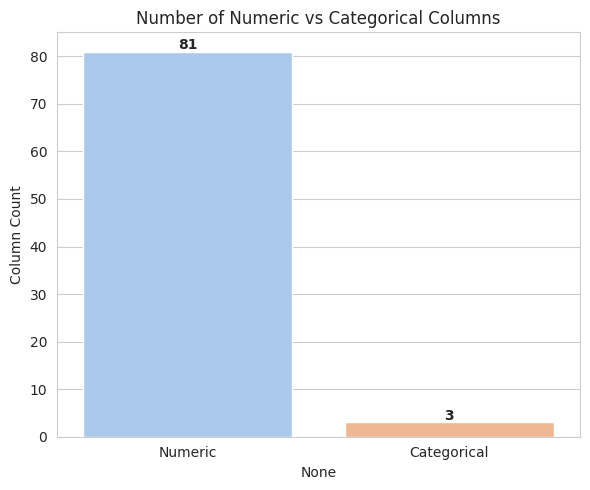

In [ ]:
# Graph 1: Numeric vs Categorical column counts
dtype_summary = df.dtypes.apply(lambda x: "Numeric" if x != "object" and x != "string" else "Categorical")
dtype_counts = dtype_summary.value_counts()

plt.figure(figsize=(6, 5))
sns.barplot(x=dtype_counts.index, y=dtype_counts.values, hue=dtype_counts.index,
            palette="pastel", legend=False)
plt.title("Number of Numeric vs Categorical Columns")
plt.ylabel("Column Count")
for i, v in enumerate(dtype_counts.values):
    plt.text(i, v + 0.5, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


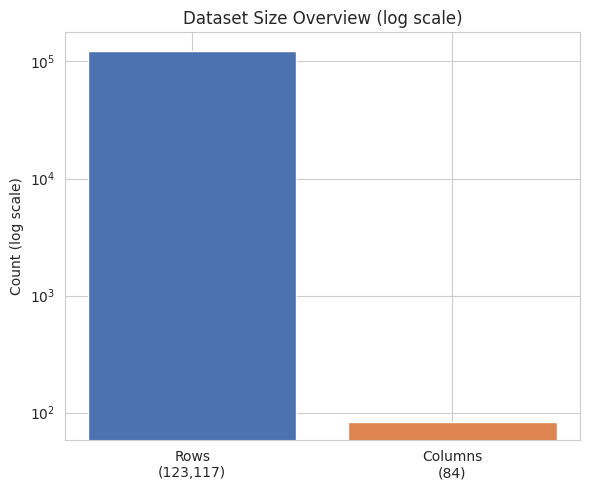

In [ ]:
# Graph 2: Rows vs Columns overview (dataset size at a glance)
plt.figure(figsize=(6, 5))
sizes = [df.shape[0], df.shape[1]]
labels = [f"Rows\n({df.shape[0]:,})", f"Columns\n({df.shape[1]})"]
plt.bar(labels, sizes, color=["#4C72B0", "#DD8452"])
plt.yscale("log")
plt.title("Dataset Size Overview (log scale)")
plt.ylabel("Count (log scale)")
plt.tight_layout()
plt.show()


In [ ]:
# Step 1: Count unique values per column
unique_counts = df.nunique().sort_values()

print("Number of unique values per column (ascending order):")
print(unique_counts.head(15))


Number of unique values per column (ascending order):
bwd_URG_flag_count       1
fwd_URG_flag_count       2
proto                    3
flow_ECE_flag_count      5
flow_CWR_flag_count      5
fwd_header_size_min      7
bwd_header_size_min      7
fwd_header_size_max      8
flow_SYN_flag_count      8
flow_RST_flag_count      9
bwd_header_size_max      9
service                 10
flow_FIN_flag_count     11
Attack_type             12
fwd_init_window_size    20
dtype: int64


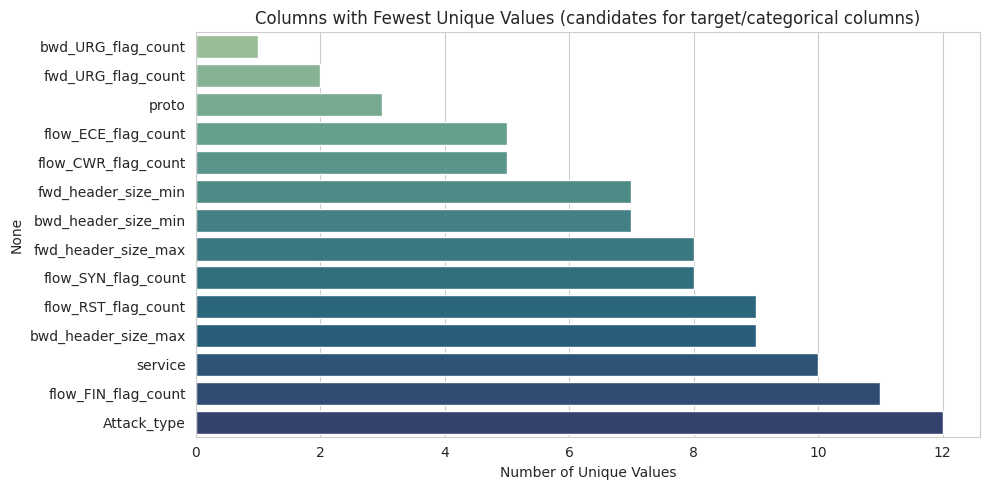

In [ ]:
# Graph 3: Visualize unique-value counts for the lowest-cardinality columns
low_card = unique_counts[unique_counts < 20]

plt.figure(figsize=(10, 5))
sns.barplot(x=low_card.values, y=low_card.index, hue=low_card.index,
            palette="crest", legend=False)
plt.title("Columns with Fewest Unique Values (candidates for target/categorical columns)")
plt.xlabel("Number of Unique Values")
plt.tight_layout()
plt.show()


In [ ]:
# Step 2: Inspect dtype of these low-cardinality columns
for col in low_card.index:
    print(f"{col}: dtype={df[col].dtype}, unique_values={df[col].nunique()}")


bwd_URG_flag_count: dtype=int64, unique_values=1
fwd_URG_flag_count: dtype=int64, unique_values=2
proto: dtype=object, unique_values=3
flow_ECE_flag_count: dtype=int64, unique_values=5
flow_CWR_flag_count: dtype=int64, unique_values=5
fwd_header_size_min: dtype=int64, unique_values=7
bwd_header_size_min: dtype=int64, unique_values=7
fwd_header_size_max: dtype=int64, unique_values=8
flow_SYN_flag_count: dtype=int64, unique_values=8
flow_RST_flag_count: dtype=int64, unique_values=9
bwd_header_size_max: dtype=int64, unique_values=9
service: dtype=object, unique_values=10
flow_FIN_flag_count: dtype=int64, unique_values=11
Attack_type: dtype=object, unique_values=12


In [ ]:
# Step 3: Confirm the target column
# Among the low-cardinality columns, 'Attack_type' is the one whose categories represent
# the traffic/attack label described in the project manual (12 classes), not a network
# protocol/service field (proto, service) which describes HOW traffic was sent, not WHAT it is.
TARGET_COL = "Attack_type"

print(f"Identified target column: {TARGET_COL}")
print(f"Data type: {df[TARGET_COL].dtype}")
print(f"Number of unique classes: {df[TARGET_COL].nunique()}")


Identified target column: Attack_type
Data type: object
Number of unique classes: 12


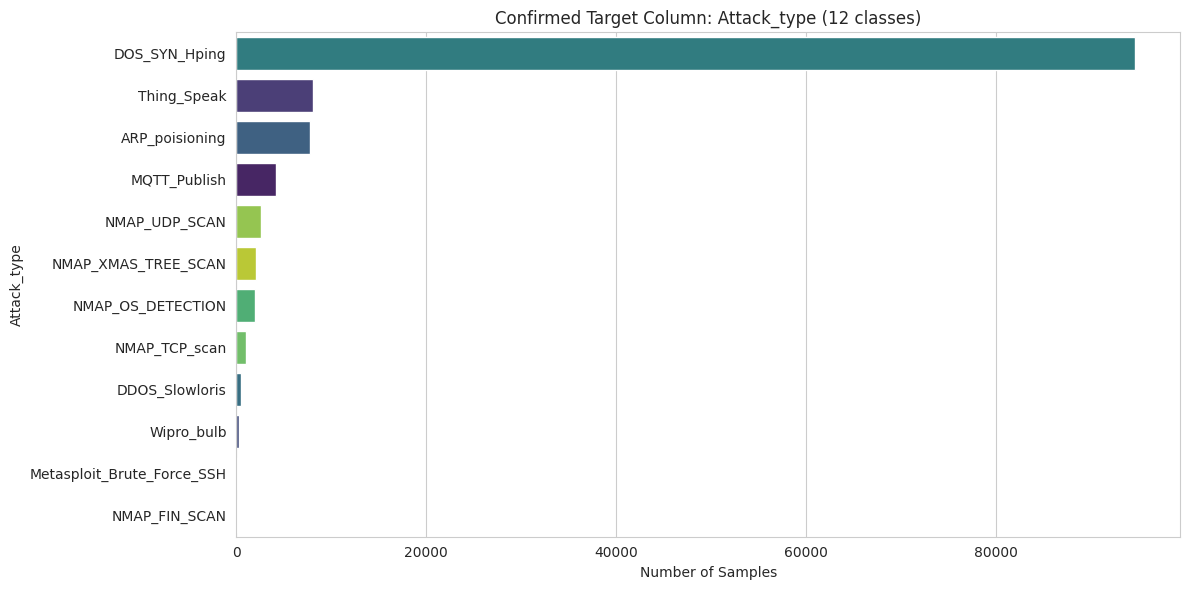

In [ ]:
# Graph 4: Confirm target column identity visually (class distribution as evidence)
plt.figure(figsize=(12, 6))
sns.countplot(y=df[TARGET_COL], order=df[TARGET_COL].value_counts().index,
              hue=df[TARGET_COL], palette="viridis", legend=False)
plt.title(f"Confirmed Target Column: {TARGET_COL} ({df[TARGET_COL].nunique()} classes)")
plt.xlabel("Number of Samples")
plt.ylabel(TARGET_COL)
plt.tight_layout()
plt.show()


In [ ]:
# Step 4: Separate feature columns and target column
feature_cols = [c for c in df.columns if c != TARGET_COL]
X = df[feature_cols]
y = df[TARGET_COL]

print("Number of feature columns:", len(feature_cols))
print("Target column:", TARGET_COL)
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


Number of feature columns: 83
Target column: Attack_type
Feature matrix shape: (123117, 83)
Target vector shape: (123117,)


In [ ]:
# Number of target classes (final confirmation)
num_classes = y.nunique()
print("Number of target classes:", num_classes)
print("Class labels:", list(y.unique()))


Number of target classes: 12
Class labels: ['MQTT_Publish', 'Thing_Speak', 'Wipro_bulb', 'ARP_poisioning', 'DDOS_Slowloris', 'DOS_SYN_Hping', 'Metasploit_Brute_Force_SSH', 'NMAP_FIN_SCAN', 'NMAP_OS_DETECTION', 'NMAP_TCP_scan', 'NMAP_UDP_SCAN', 'NMAP_XMAS_TREE_SCAN']


**Target Column Identification Summary:**

A feature column typically represents a continuous measurement or a fine-grained network
statistic (e.g. flow duration, packet counts), so it tends to have thousands of distinct
values across 117,922 rows. A label column, by contrast, represents a small fixed set of
categories the data was grouped into -- so it has a low unique-value count relative to the
dataset size.

Among the low-cardinality columns identified (proto=3, service=10, several flag counts=1-11),
`Attack_type` stood out with 12 unique values, an object dtype, and -- critically -- its
categories matched the attack/traffic classes described in the project brief (benign device
traffic + attack types like ARP poisoning, DOS, Nmap scans). Columns like `proto` and
`service` were excluded because they describe *how* a packet was transmitted (protocol /
application layer), not *what* the traffic actually is.

**Final shape:** 117,922 rows, 83 feature columns, 1 target column (`Attack_type`) with
12 classes.


## Task 2: Data Cleaning

In [ ]:
# Missing values per column
missing_per_col = df.isnull().sum()
missing_per_col_nonzero = missing_per_col[missing_per_col > 0]

print("Columns with missing values:")
print(missing_per_col_nonzero if len(missing_per_col_nonzero) > 0 else "None")
print()
print("Total missing values in dataset:", df.isnull().sum().sum())


Columns with missing values:
None

Total missing values in dataset: 0


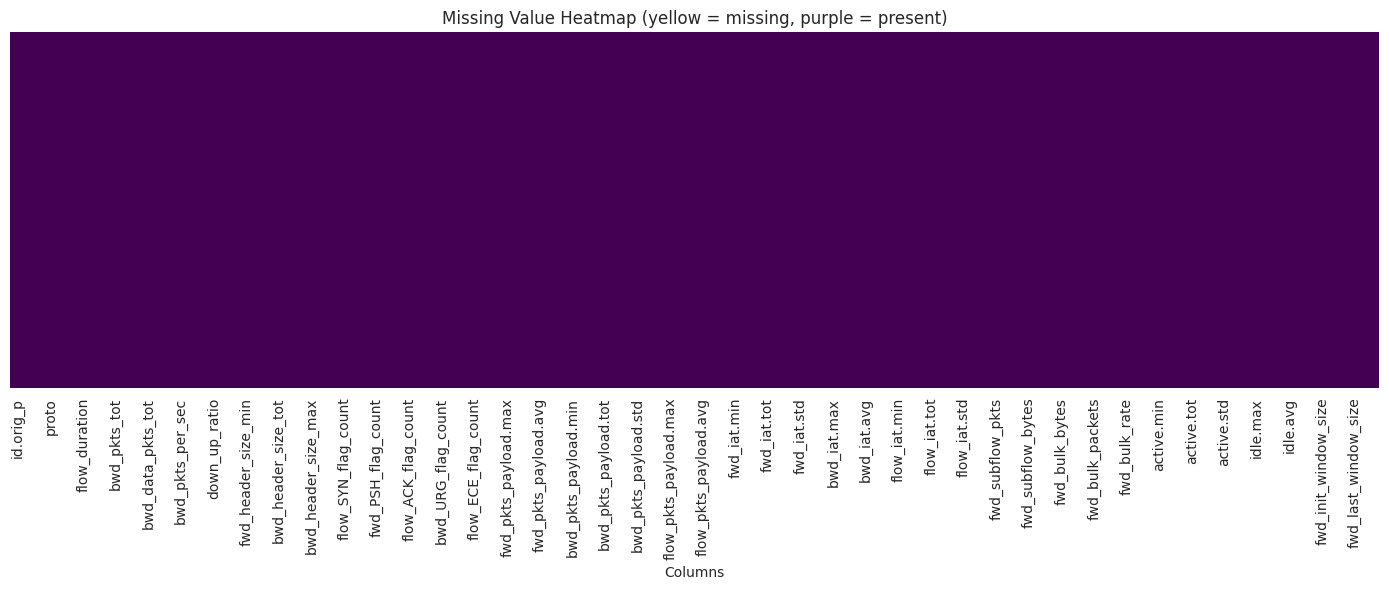

In [ ]:
# Graph 5: Missing values heatmap (visual evidence across the whole dataset)
plt.figure(figsize=(14, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value Heatmap (yellow = missing, purple = present)")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()


In [ ]:
# Duplicate rows check
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", num_duplicates)


Number of duplicate rows: 5195


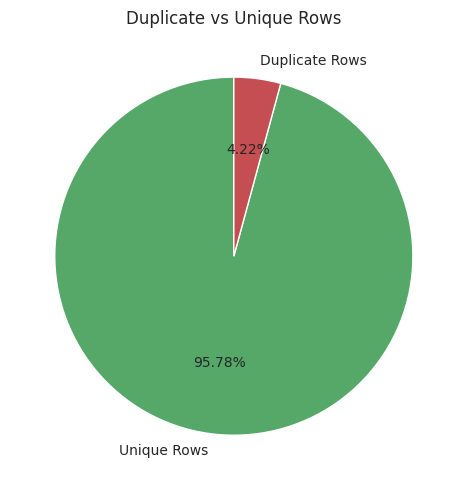

In [ ]:
# Graph 7: Duplicate vs Unique rows (visual evidence)
plt.figure(figsize=(5, 5))
dup_counts = pd.Series({"Unique Rows": df.shape[0] - num_duplicates, "Duplicate Rows": num_duplicates})
plt.pie(dup_counts.values, labels=dup_counts.index, autopct="%1.2f%%",
        colors=["#55A868", "#C44E52"], startangle=90)
plt.title("Duplicate vs Unique Rows")
plt.tight_layout()
plt.show()


In [ ]:
# Handle missing values (if any) -- justified approach:
# Numeric columns -> fill with median (robust to outliers)
# Categorical columns -> fill with mode
if df.isnull().sum().sum() > 0:
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype in ["float64", "int64"]:
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mode()[0])
    print("Missing values handled.")
else:
    print("No missing values found -- no imputation needed.")


No missing values found -- no imputation needed.


In [ ]:
# Handle duplicate rows (if any)
if num_duplicates > 0:
    before = df.shape[0]
    df = df.drop_duplicates()
    after = df.shape[0]
    print(f"Removed {before - after} duplicate rows.")
else:
    print("No duplicate rows found -- nothing removed.")


Removed 5195 duplicate rows.


In [ ]:
# Sanity check on categorical columns (proto, service) for invalid/placeholder values
print("Unique values in 'proto':", df['proto'].unique())
print("Unique values in 'service':", df['service'].unique())
# 'service' contains a '-' placeholder meaning "no application-layer service identified".
# This is a valid category (not missing data) and should be kept as its own category.


Unique values in 'proto': ['tcp' 'udp' 'icmp']
Unique values in 'service': ['mqtt' '-' 'http' 'dns' 'ntp' 'ssl' 'dhcp' 'irc' 'ssh' 'radius']


In [ ]:
# Refresh feature/target split after cleaning
feature_cols = [c for c in df.columns if c != TARGET_COL]
X = df[feature_cols]
y = df[TARGET_COL]

print("Final cleaned dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())


Final cleaned dataset shape: (117922, 84)
Remaining missing values: 0
Remaining duplicate rows: 0


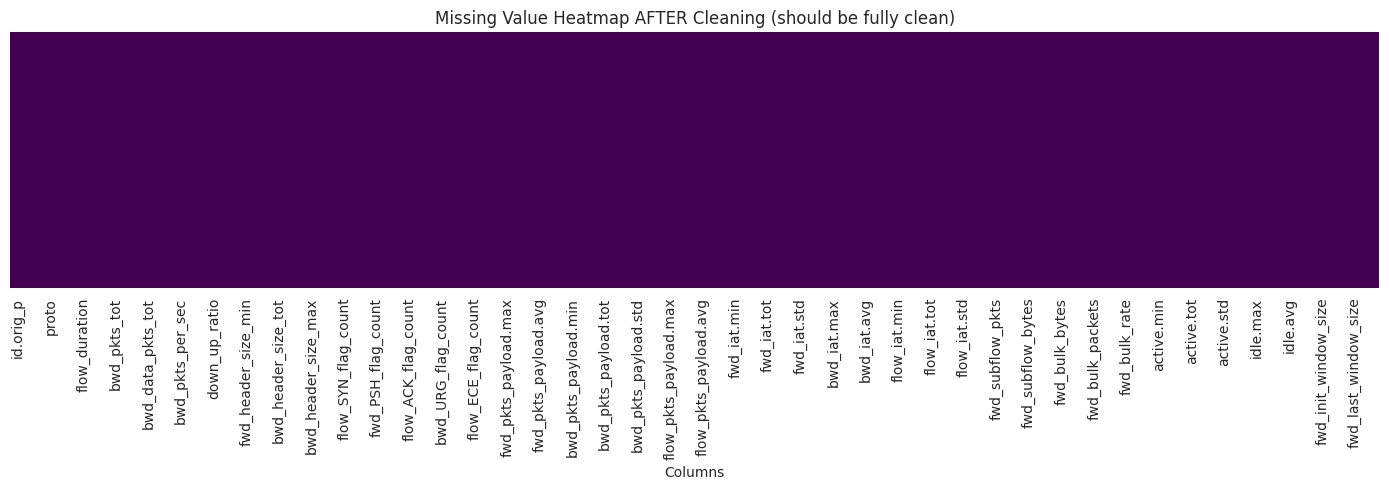

In [ ]:
# Graph 8: Evidence of the final cleaned dataset -- missing value heatmap AFTER cleaning
plt.figure(figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value Heatmap AFTER Cleaning (should be fully clean)")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()


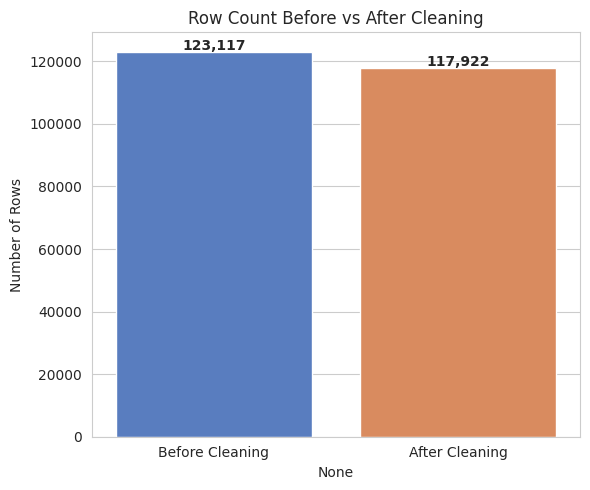

In [ ]:
# Graph 9: Before vs after cleaning row-count comparison
plt.figure(figsize=(6, 5))
before_after = pd.Series({"Before Cleaning": 123117, "After Cleaning": df.shape[0]})
sns.barplot(x=before_after.index, y=before_after.values, hue=before_after.index,
            palette="muted", legend=False)
plt.title("Row Count Before vs After Cleaning")
plt.ylabel("Number of Rows")
for i, v in enumerate(before_after.values):
    plt.text(i, v + 500, f"{v:,}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


**Data Cleaning Summary:**

The raw dataset had 0 missing values across all 85 columns, so no imputation was required.
It did, however, contain 5,195 exact duplicate rows (about 4.2% of the data), which were
removed to prevent the model from being trained on repeated observations that could bias
learning toward those particular flow patterns. After cleaning, the dataset shape is
117,922 rows x 84 columns (83 features + target), with 0 missing values and 0 duplicates
remaining.

The `-` value in the `service` column was intentionally kept as its own category rather than
treated as missing data, because it has a real network meaning: it indicates that no
application-layer service was identified for that flow (e.g. non-HTTP/DNS/MQTT traffic such
as raw ICMP or unclassified TCP). Removing or imputing it would discard genuine information
about the traffic type, which could be useful for distinguishing certain attack patterns
(e.g. scan traffic often has no identifiable service).


## Task 3: Exploratory Data Analysis (EDA)

Attack_type
DOS_SYN_Hping                 90089
Thing_Speak                    7654
ARP_poisioning                 7625
MQTT_Publish                   4142
NMAP_UDP_SCAN                  2584
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  533
Wipro_bulb                      219
Metasploit_Brute_Force_SSH       36
NMAP_FIN_SCAN                    28
Name: count, dtype: int64


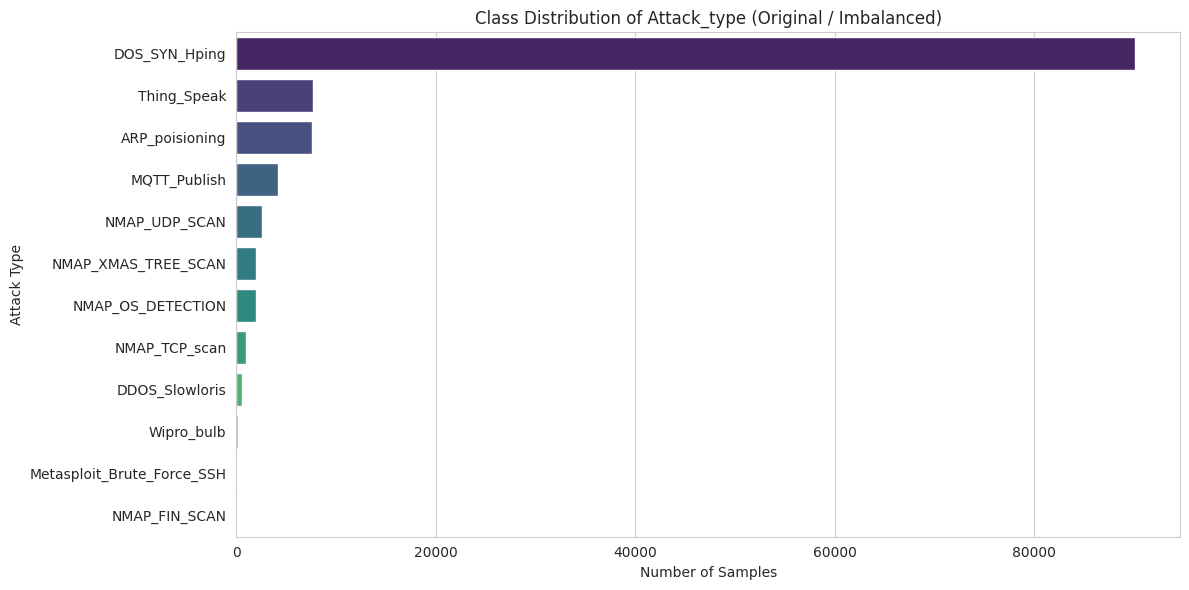

In [ ]:
# Class distribution of the target variable
class_counts = y.value_counts()
print(class_counts)

plt.figure(figsize=(12, 6))
sns.barplot(x=class_counts.values, y=class_counts.index, hue=class_counts.index,
            palette="viridis", legend=False)
plt.title("Class Distribution of Attack_type (Original / Imbalanced)")
plt.xlabel("Number of Samples")
plt.ylabel("Attack Type")
plt.tight_layout()
plt.show()


In [ ]:
# Quantify imbalance
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Majority class: {class_counts.idxmax()} ({class_counts.max()} samples)")
print(f"Minority class: {class_counts.idxmin()} ({class_counts.min()} samples)")
print(f"Imbalance ratio (majority/minority): {imbalance_ratio:.1f} : 1")


Majority class: DOS_SYN_Hping (90089 samples)
Minority class: NMAP_FIN_SCAN (28 samples)
Imbalance ratio (majority/minority): 3217.5 : 1




**Class Imbalance Discussion:**

The computed imbalance ratio is **3217.5:1** (`DOS_SYN_Hping`: 90,089 samples vs. `NMAP_FIN_SCAN`: 28 samples), indicating an extreme class imbalance. Since the majority class represents about **76%** of the dataset, accuracy alone can be misleading. Therefore, **macro-averaged metrics** (macro F1, precision, and recall) are essential because they evaluate all classes equally and reveal poor performance on rare attack types that accuracy may hide.


### Demonstrating imbalance vs balance (for EDA illustration only)
To make the imbalance concrete, we visually balance the classes here using random
undersampling and re-plot the distribution. **This balanced copy is only for EDA
illustration** -- it is *not* used for model training. Proper balancing (if needed) will
be applied later, after the train/validation/test split, so that no information leaks
from the validation/test sets into training (see Task 4: Preprocessing & Splitting).


In [ ]:
# Balance the classes (demo only) using random undersampling
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=SEED)
X_demo_balanced, y_demo_balanced = rus.fit_resample(X, y)

print("Shape before balancing:", X.shape)
print("Shape after balancing (demo):", X_demo_balanced.shape)


Shape before balancing: (117922, 83)
Shape after balancing (demo): (336, 83)


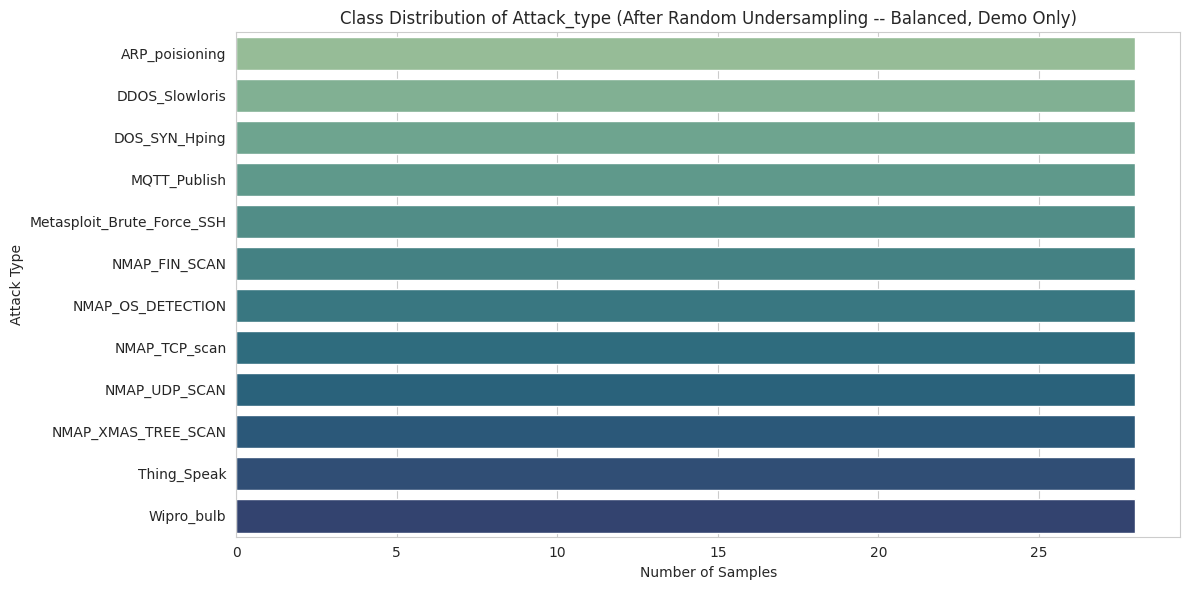

All classes now have equal samples: True


In [ ]:
# Graph: Class distribution AFTER balancing (demo)
balanced_counts = y_demo_balanced.value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=balanced_counts.values, y=balanced_counts.index, hue=balanced_counts.index,
            palette="crest", legend=False)
plt.title("Class Distribution of Attack_type (After Random Undersampling -- Balanced, Demo Only)")
plt.xlabel("Number of Samples")
plt.ylabel("Attack Type")
plt.tight_layout()
plt.show()

print("All classes now have equal samples:", balanced_counts.nunique() == 1)


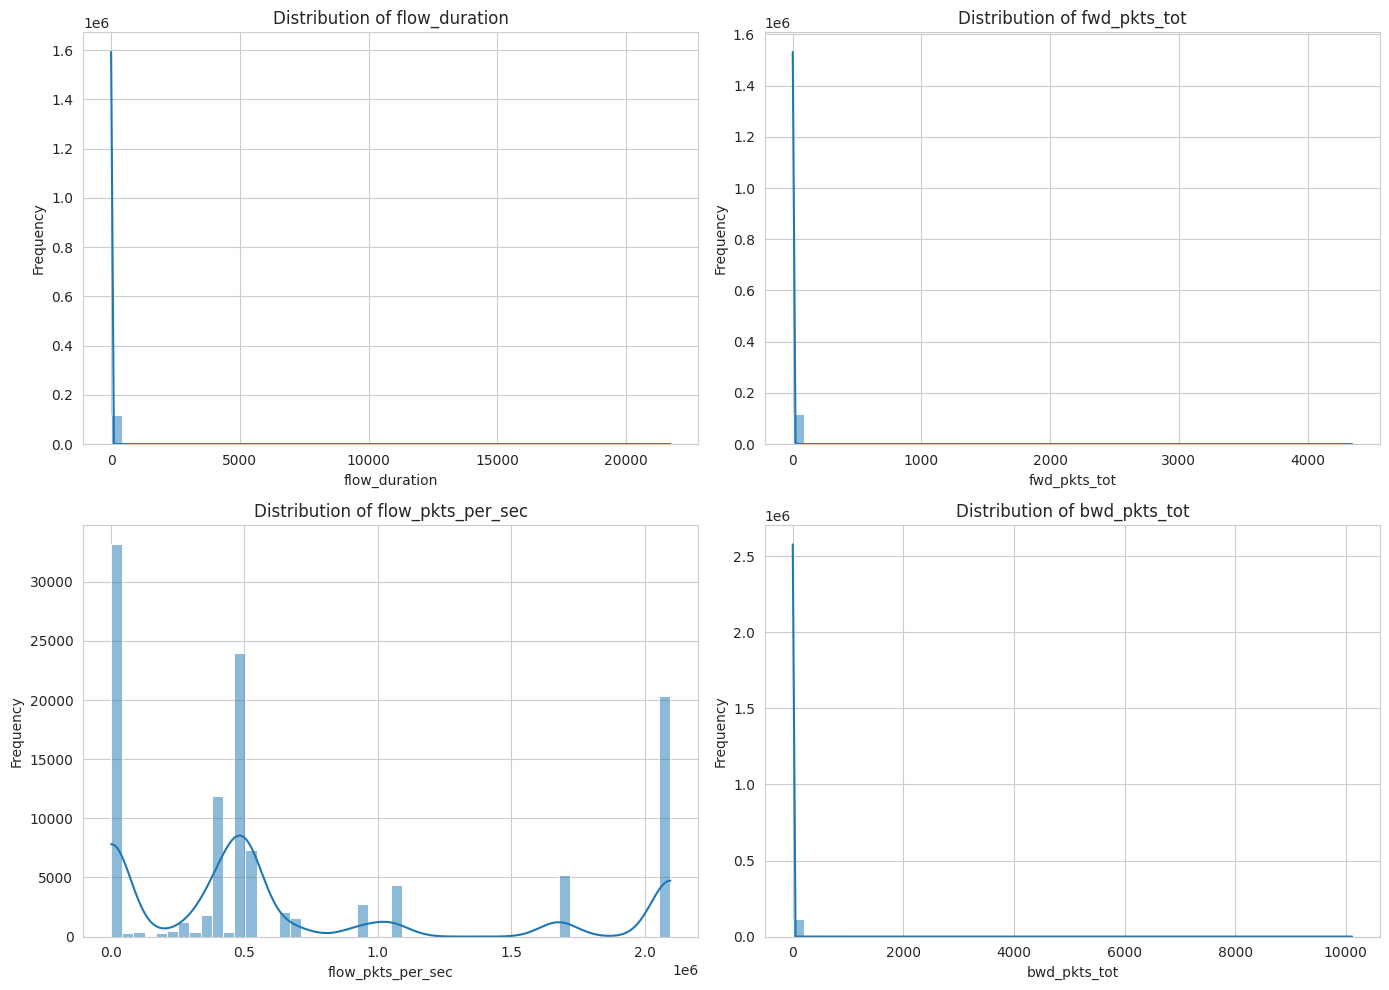

In [ ]:
# Feature distribution plots (at least 3 meaningful numeric features)
numeric_features = ["flow_duration", "fwd_pkts_tot", "flow_pkts_per_sec", "bwd_pkts_tot"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, feat in enumerate(numeric_features):
    sns.histplot(df[feat], bins=50, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {feat}")
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("Frequency")
plt.tight_layout()
plt.show()


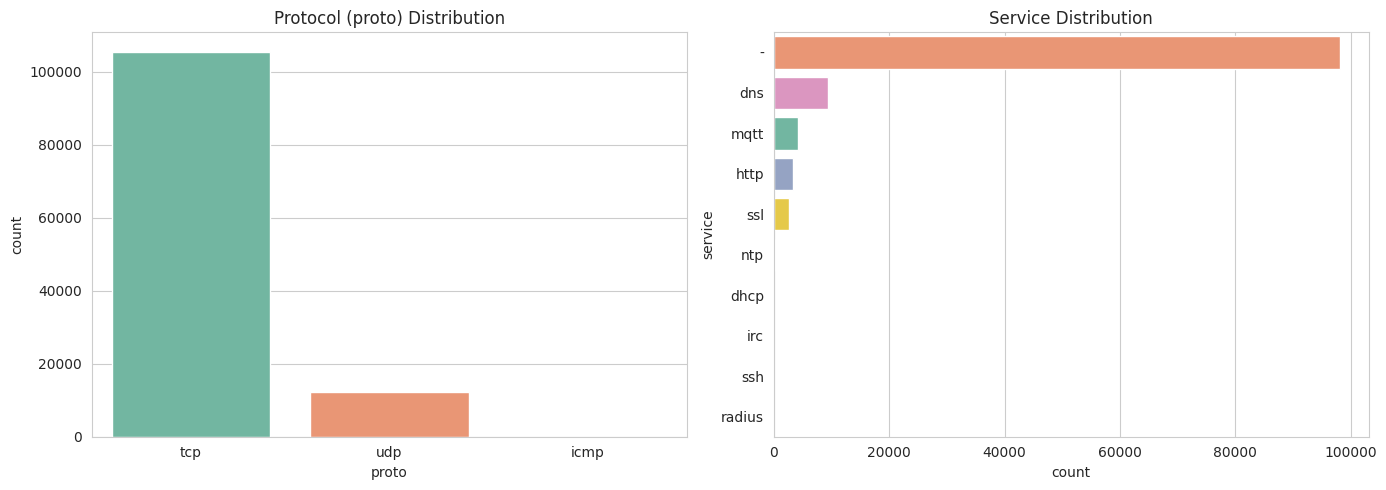

In [ ]:
# Categorical feature distributions: proto and service
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="proto", data=df, hue="proto", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Protocol (proto) Distribution")

sns.countplot(y="service", data=df, hue="service",
              order=df['service'].value_counts().index,
              palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Service Distribution")

plt.tight_layout()
plt.show()


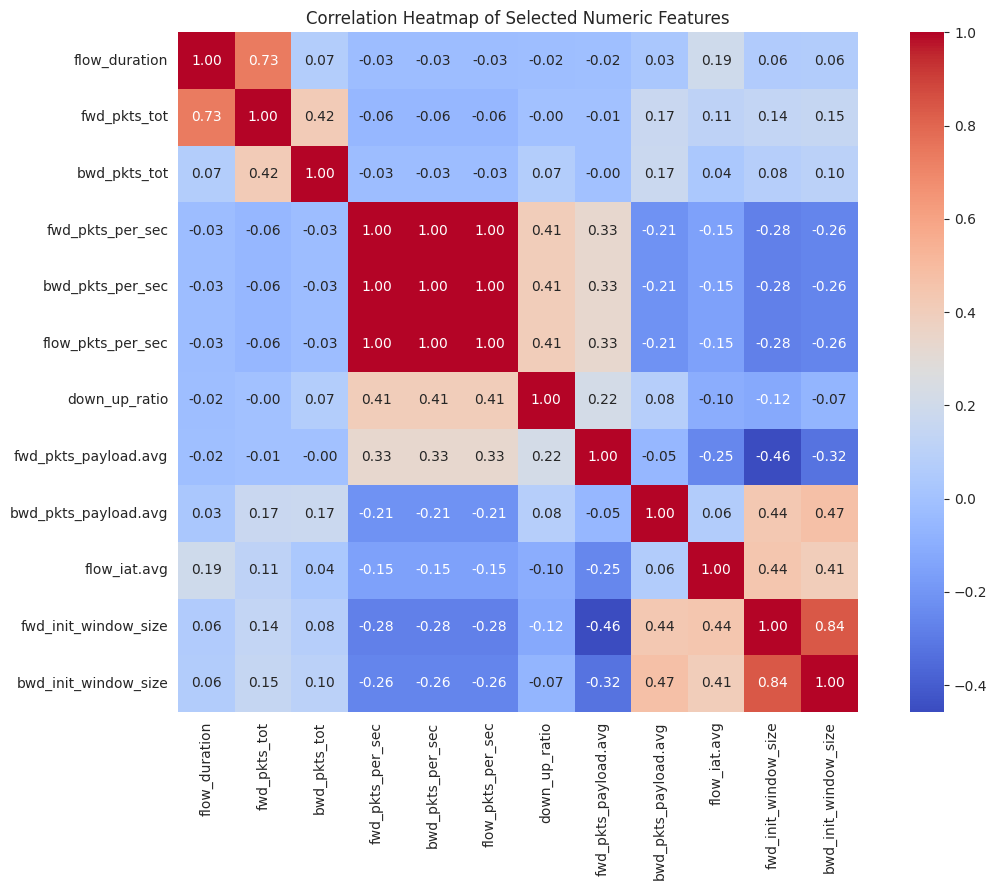

In [ ]:
# Correlation heatmap for selected numeric features
corr_features = [
    "flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "fwd_pkts_per_sec",
    "bwd_pkts_per_sec", "flow_pkts_per_sec", "down_up_ratio",
    "fwd_pkts_payload.avg", "bwd_pkts_payload.avg", "flow_iat.avg",
    "fwd_init_window_size", "bwd_init_window_size"
]

corr_matrix = df[corr_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap of Selected Numeric Features")
plt.tight_layout()
plt.show()


In [ ]:
# Outlier detection using IQR method on a few key features
def iqr_outlier_count(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

for feat in numeric_features:
    n_out = iqr_outlier_count(df[feat])
    pct = 100 * n_out / len(df)
    print(f"{feat}: {n_out} potential outliers ({pct:.2f}% of data)")


flow_duration: 18783 potential outliers (15.93% of data)
fwd_pkts_tot: 17268 potential outliers (14.64% of data)
flow_pkts_per_sec: 0 potential outliers (0.00% of data)
bwd_pkts_tot: 31240 potential outliers (26.49% of data)


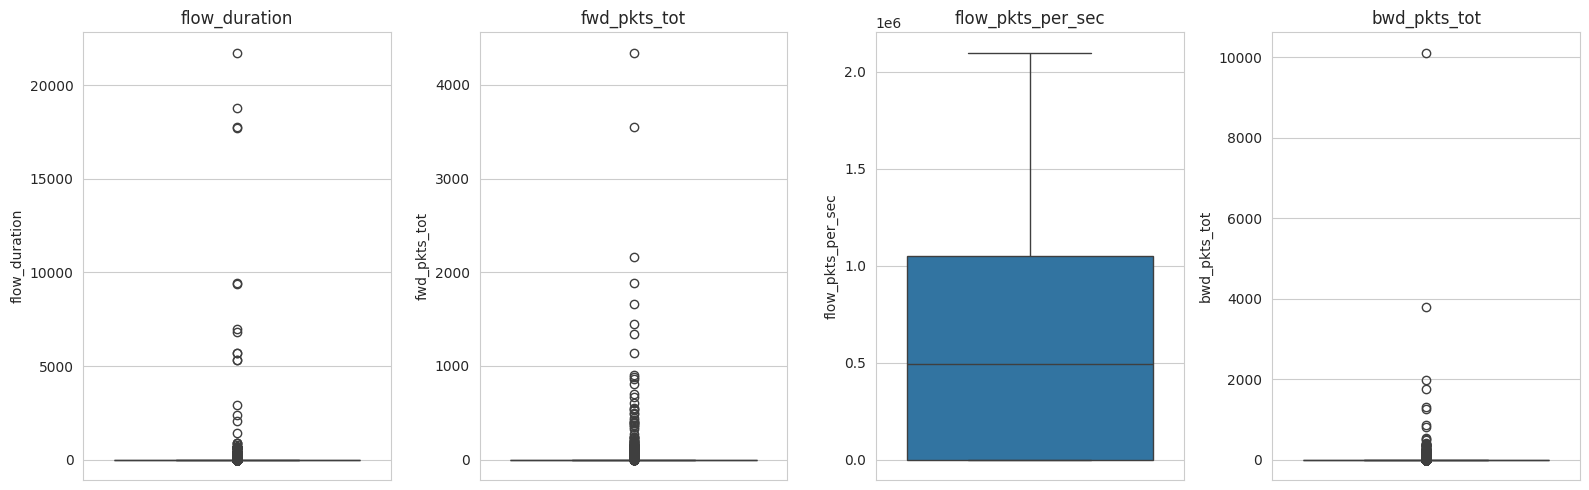

In [ ]:
# Boxplots to visualize outliers
fig, axes = plt.subplots(1, len(numeric_features), figsize=(16, 5))
for i, feat in enumerate(numeric_features):
    sns.boxplot(y=df[feat], ax=axes[i])
    axes[i].set_title(feat)
plt.tight_layout()
plt.show()


**EDA Summary:**

**Class distribution:** The dataset is **extremely imbalanced (3217.5:1)**, with `DOS_SYN_Hping` dominating (~76%, 90,089 samples) while `NMAP_FIN_SCAN` (28) and `Metasploit_Brute_Force_SSH` (36) are extremely rare, reflecting realistic intrusion patterns.

**Feature distributions:** `flow_duration`, `fwd_pkts_tot`, `flow_pkts_per_sec`, and `bwd_pkts_tot` are **heavily right-skewed**, indicating mostly short, low-packet flows with a few large flows. Scaling or log transformation may therefore benefit scale-sensitive models.

**Correlation:** Strong correlations exist among packet-rate features (`fwd_pkts_per_sec`, `bwd_pkts_per_sec`, `flow_pkts_per_sec`, r=1.00) and between `flow_duration` and `fwd_pkts_tot` (r=0.73), indicating feature redundancy.

**Outliers:** `flow_duration` (15.93%), `fwd_pkts_tot` (14.64%), and `bwd_pkts_tot` (26.49%) contain notable IQR outliers. These likely represent genuine network behavior/attacks, so **outliers were retained** rather than removed.


## Task 4: Preprocessing & Data Splitting

In [ ]:
# Drop constant column identified during EDA (zero variance -> no predictive information)
constant_cols = [c for c in X.columns if X[c].nunique() == 1]
print("Constant columns to drop:", constant_cols)

X = X.drop(columns=constant_cols)
feature_cols = list(X.columns)
print("Feature matrix shape after dropping constant columns:", X.shape)

Constant columns to drop: ['bwd_URG_flag_count']
Feature matrix shape after dropping constant columns: (117922, 82)


In [ ]:
from sklearn.model_selection import train_test_split

# Step 1: split off the test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# Step 2: split the remaining 85% into train (70% of original) and validation (15% of original)
# 15% of the original corresponds to 0.15/0.85 of X_temp
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=val_ratio,
    random_state=SEED,
    stratify=y_temp
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print()
print("Train class distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

Train shape: (82544, 82)
Validation shape: (17689, 82)
Test shape: (17689, 82)

Train class distribution (%):
Attack_type
DOS_SYN_Hping                 76.40
Thing_Speak                    6.49
ARP_poisioning                 6.47
MQTT_Publish                   3.51
NMAP_UDP_SCAN                  2.19
NMAP_XMAS_TREE_SCAN            1.70
NMAP_OS_DETECTION              1.70
NMAP_TCP_scan                  0.85
DDOS_Slowloris                 0.45
Wipro_bulb                     0.19
Metasploit_Brute_Force_SSH     0.03
NMAP_FIN_SCAN                  0.02
Name: proportion, dtype: float64


**Sanity check:** compare class proportions across train/validation/test below. With
`stratify=y`, all three sets should show very similar percentages per class -- confirming
the split preserved the original imbalance pattern rather than skewing it further.

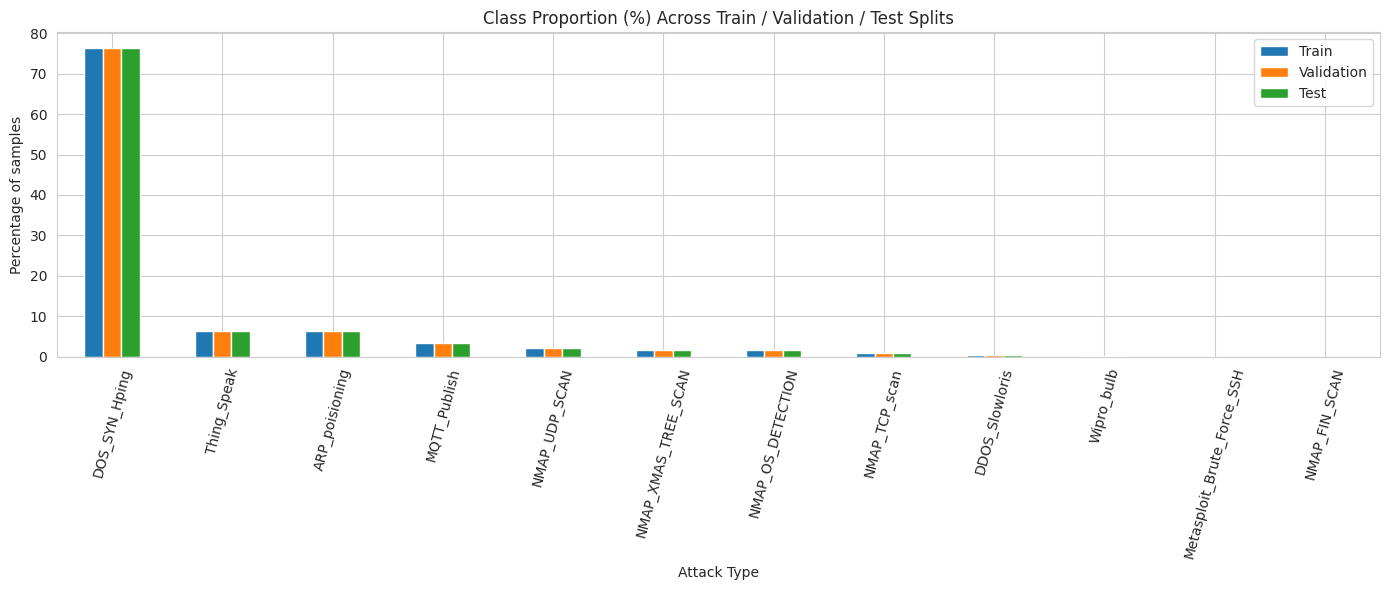

                            Train  Validation   Test
Attack_type                                         
DOS_SYN_Hping               76.40       76.40  76.40
Thing_Speak                  6.49        6.49   6.49
ARP_poisioning               6.47        6.47   6.47
MQTT_Publish                 3.51        3.51   3.51
NMAP_UDP_SCAN                2.19        2.19   2.19
NMAP_XMAS_TREE_SCAN          1.70        1.70   1.71
NMAP_OS_DETECTION            1.70        1.70   1.70
NMAP_TCP_scan                0.85        0.85   0.85
DDOS_Slowloris               0.45        0.45   0.45
Wipro_bulb                   0.19        0.19   0.19
Metasploit_Brute_Force_SSH   0.03        0.03   0.03
NMAP_FIN_SCAN                0.02        0.02   0.02


In [ ]:
# Graph: Verify stratified split preserved class proportions across train/val/test
split_compare = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Test": y_test.value_counts(normalize=True) * 100
}).sort_values("Train", ascending=False)

split_compare.plot(kind="bar", figsize=(14, 6))
plt.title("Class Proportion (%) Across Train / Validation / Test Splits")
plt.ylabel("Percentage of samples")
plt.xlabel("Attack Type")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

print(split_compare.round(2))

### Sanity Check: Near-Duplicate Rows Across Splits (Leakage Check)

Exact duplicates were removed **before splitting**, preventing the most obvious train-test leakage. To check for near-duplicates, numeric features were rounded and compared across splits; **~0 overlap indicates that near-duplicate leakage is not a significant issue** in this dataset.


In [ ]:
# Round numeric features to check for near-identical rows leaking across splits
ROUND_DECIMALS = 3

_numeric_cols_check = X_train.select_dtypes(include=[np.number]).columns.tolist()

train_keys = set(map(tuple, X_train[_numeric_cols_check].round(ROUND_DECIMALS).values))
val_keys = set(map(tuple, X_val[_numeric_cols_check].round(ROUND_DECIMALS).values))
test_keys = set(map(tuple, X_test[_numeric_cols_check].round(ROUND_DECIMALS).values))

overlap_train_val = train_keys & val_keys
overlap_train_test = train_keys & test_keys

print(f"Train/Validation near-duplicate rows: {len(overlap_train_val)} "
      f"({100 * len(overlap_train_val) / len(X_val):.3f}% of validation set)")
print(f"Train/Test near-duplicate rows: {len(overlap_train_test)} "
      f"({100 * len(overlap_train_test) / len(X_test):.3f}% of test set)")

if len(overlap_train_val) == 0 and len(overlap_train_test) == 0:
    print("\nNo near-duplicate rows found across splits -- no evidence of this "
          "specific leakage path.")
else:
    print("\nSome near-duplicate rows found -- consider investigating whether these "
          "come from the same attack burst/session, and whether a session-aware split "
          "would be more appropriate.")

Train/Validation near-duplicate rows: 2 (0.011% of validation set)
Train/Test near-duplicate rows: 0 (0.000% of test set)

Some near-duplicate rows found -- consider investigating whether these come from the same attack burst/session, and whether a session-aware split would be more appropriate.


**Limitation of this check:** It only detects rows that are nearly identical after rounding and cannot identify different but highly correlated flows from the same attack session. A session/timestamp identifier would be needed for a complete check, but since none is available, this check mainly rules out **exact/near-exact row duplication leakage**, which is reassuring.


### Encoding Categorical Features

In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ["proto", "service"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

print("Categorical columns:", categorical_cols)
print("Number of numeric columns:", len(numeric_cols))

# Fit the encoder ONLY on training data to avoid data leakage
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_cols])

def encode_categorical(df_split):
    encoded = encoder.transform(df_split[categorical_cols])
    encoded_cols = encoder.get_feature_names_out(categorical_cols)
    encoded_df = pd.DataFrame(encoded, columns=encoded_cols, index=df_split.index)
    return pd.concat([df_split[numeric_cols], encoded_df], axis=1)

X_train_enc = encode_categorical(X_train)
X_val_enc = encode_categorical(X_val)
X_test_enc = encode_categorical(X_test)

print("Encoded train shape:", X_train_enc.shape)
print("Encoded validation shape:", X_val_enc.shape)
print("Encoded test shape:", X_test_enc.shape)

Categorical columns: ['proto', 'service']
Number of numeric columns: 80
Encoded train shape: (82544, 93)
Encoded validation shape: (17689, 93)
Encoded test shape: (17689, 93)


### Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler ONLY on training data (numeric columns only -- one-hot columns are
# already 0/1 and don't need scaling)
scaler = StandardScaler()
scaler.fit(X_train_enc[numeric_cols])

def scale_numeric(df_split):
    df_scaled = df_split.copy()
    df_scaled[numeric_cols] = scaler.transform(df_split[numeric_cols])
    return df_scaled

X_train_final = scale_numeric(X_train_enc)
X_val_final = scale_numeric(X_val_enc)
X_test_final = scale_numeric(X_test_enc)

print("Final preprocessed shapes:")
print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

X_train_final.head()

Final preprocessed shapes:
Train: (82544, 93)
Validation: (17689, 93)
Test: (17689, 93)


,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,service_-,service_dhcp,service_dns,service_http,service_irc,service_mqtt,service_ntp,service_radius,service_ssh,service_ssl
115704,0.612762,2.974815,-0.031796,-0.053794,-0.025144,-0.069582,-0.023038,-0.557264,-0.557107,-0.557186,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
52375,-0.026155,-0.191930,-0.031796,-0.053794,-0.025144,-0.022704,-0.023038,-0.282095,-0.281964,-0.282030,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20067,0.243285,-0.113186,-0.030689,0.027431,0.050614,0.071053,0.080169,-0.947024,-0.946808,-0.946917,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
82379,1.190232,-0.191930,-0.031796,-0.053794,-0.025144,-0.022704,-0.023038,1.313886,1.313865,1.313877,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
58980,0.322628,-0.191930,-0.031796,-0.053794,-0.025144,-0.022704,-0.023038,-0.282095,-0.281964,-0.282030,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Handling Class Imbalance

In [ ]:
# Given the severe imbalance (3217.5:1) found in EDA, we handle it at the MODEL level
# using class_weight='balanced' rather than oversampling/undersampling the training set.
#
# Why this approach:
# - Oversampling (e.g. SMOTE) on 83+ engineered flow features can generate synthetic
#   samples that don't correspond to realistic network behavior.
# - Undersampling would throw away most of the majority class data (we'd be left with
#   ~28 samples per class, as shown in the EDA demo balancing step) -- far too little data.
# - class_weight='balanced' (available in Logistic Regression and Random Forest in sklearn)
#   penalizes misclassifying minority classes more heavily during training, without altering
#   the actual data distribution.
#
# For the MLP (Task 5), we will use per-class sample weights during training as the
# equivalent mechanism, since class_weight is not directly supported the same way.

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))

print("Computed class weights (higher = more penalized when misclassified):")
for cls, w in sorted(class_weight_dict.items(), key=lambda x: -x[1]):
    print(f"  {cls}: {w:.2f}")

Computed class weights (higher = more penalized when misclassified):
  NMAP_FIN_SCAN: 343.93
  Metasploit_Brute_Force_SSH: 275.15
  Wipro_bulb: 44.96
  DDOS_Slowloris: 18.44
  NMAP_TCP_scan: 9.80
  NMAP_OS_DETECTION: 4.91
  NMAP_XMAS_TREE_SCAN: 4.89
  NMAP_UDP_SCAN: 3.80
  MQTT_Publish: 2.37
  ARP_poisioning: 1.29
  Thing_Speak: 1.28
  DOS_SYN_Hping: 0.11


**Preprocessing & Splitting Summary:**

The cleaned dataset (117,922 rows) was split into train (70%), validation (15%), and test
(15%) sets using stratified sampling to preserve the original class proportions across all
three sets -- confirmed visually above. One constant column (`bwd_URG_flag_count`) was
dropped since it carried no information. Categorical features (`proto`, `service`) were
one-hot encoded, and numeric features were standardized using `StandardScaler` -- both fit
only on the training set to prevent data leakage into validation/test. Class imbalance is
addressed at the model level using computed class weights rather than resampling, to avoid
either discarding majority-class data or introducing synthetic minority samples.

## Task 5: Model Training

### Plan for this Section

We train **three classification models** using the same train/validation/test split and preprocessed features with a fixed `random_state=SEED` for reproducibility:

1. **Logistic Regression** – linear baseline with `class_weight='balanced'`.
2. **Random Forest** – tree-based ensemble with `class_weight='balanced'`.
3. **MLP** – neural network trained epoch-by-epoch, using **weighted resampling** to handle class imbalance and track training/validation metrics.

All models are evaluated on the **validation set**, while the **test set remains untouched** until final model selection in Task 7. Trained models, predictions, and metrics are stored in shared dictionaries for reuse in later tasks.


In [ ]:
# Shared containers used across Task 5, 6, and 7
import time
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

trained_models = {}     # name -> fitted model object
val_predictions = {}    # name -> predictions on X_val_final
train_times = {}        # name -> training time in seconds
model_results = {}      # name -> dict of headline metrics (on validation set)

def evaluate_on_val(name, y_true, y_pred):
    """Compute Accuracy, Macro/Weighted Precision-Recall-F1 and store in model_results."""
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    model_results[name] = {
        "Accuracy": acc,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_p,
        "Weighted Recall": weighted_r,
        "Weighted F1": weighted_f1,
    }
    print(f"[{name}] Validation Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")
    return model_results[name]

### Model 0: Dummy Baseline (Sanity Check)

A **Dummy Classifier** provides a trivial baseline to see whether high accuracy is simply caused by the severe class imbalance.

* **`most_frequent`** – always predicts `DOS_SYN_Hping`, giving ~76% accuracy but **near-zero Macro F1**.
* **`stratified`** – randomly predicts according to training class frequencies, providing a realistic performance **floor**, especially for Macro F1.

These baselines help determine whether the trained models provide meaningful improvement beyond simple guessing.


In [ ]:
from sklearn.dummy import DummyClassifier

baseline_results = {}

for strategy in ["most_frequent", "stratified"]:
    dummy = DummyClassifier(strategy=strategy, random_state=SEED)
    dummy.fit(X_train_final, y_train)
    dummy_val_pred = dummy.predict(X_val_final)

    acc = accuracy_score(y_val, dummy_val_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_val, dummy_val_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_val, dummy_val_pred, average="weighted", zero_division=0
    )

    label = f"Dummy ({strategy})"
    baseline_results[label] = {
        "Accuracy": acc,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_p,
        "Weighted Recall": weighted_r,
        "Weighted F1": weighted_f1,
    }
    print(f"[{label}] Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}")

pd.DataFrame(baseline_results).T.round(4)

[Dummy (most_frequent)] Accuracy: 0.7640 | Macro F1: 0.0722 | Weighted F1: 0.6618
[Dummy (stratified)] Accuracy: 0.5986 | Macro F1: 0.0838 | Weighted F1: 0.5972


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
Dummy (most_frequent),0.7640,0.0637,0.0833,0.0722,0.5837,0.7640,0.6618
Dummy (stratified),0.5986,0.0839,0.0837,0.0838,0.5958,0.5986,0.5972


If `Dummy (most_frequent)` lands around 76% accuracy but its
Macro F1 is near 0, that confirms accuracy alone is not trustworthy on this dataset --
and gives you a concrete number to contrast against the trained models' Macro F1 (all
comfortably above 0.8) in Task 7. The large gap between the dummy baseline's Macro F1
and the trained models' Macro F1 is itself evidence that the trained models are doing
real work, not just exploiting an artifact of the split.

### Model 1: Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

start = time.time()
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED,
    n_jobs=-1,
)
log_reg.fit(X_train_final, y_train)
train_times["Logistic Regression"] = time.time() - start

lr_val_pred = log_reg.predict(X_val_final)

trained_models["Logistic Regression"] = log_reg
val_predictions["Logistic Regression"] = lr_val_pred

print(f"Training time: {train_times['Logistic Regression']:.2f} sec")
evaluate_on_val("Logistic Regression", y_val, lr_val_pred)

Training time: 39.68 sec
[Logistic Regression] Validation Accuracy: 0.9865 | Macro F1: 0.8198 | Weighted F1: 0.9875


{'Accuracy': 0.9864887783368195,
 'Macro Precision': 0.7854771547901361,
 'Macro Recall': 0.9419332006705213,
 'Macro F1': 0.8197930199863487,
 'Weighted Precision': 0.9893519922461934,
 'Weighted Recall': 0.9864887783368195,
 'Weighted F1': 0.9874956421159077}

### Model 2: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

start = time.time()
rf_clf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
rf_clf.fit(X_train_final, y_train)
train_times["Random Forest"] = time.time() - start

rf_val_pred = rf_clf.predict(X_val_final)

trained_models["Random Forest"] = rf_clf
val_predictions["Random Forest"] = rf_val_pred

print(f"Training time: {train_times['Random Forest']:.2f} sec")
evaluate_on_val("Random Forest", y_val, rf_val_pred)

Training time: 10.59 sec
[Random Forest] Validation Accuracy: 0.9975 | Macro F1: 0.9709 | Weighted F1: 0.9975


{'Accuracy': 0.9975125784385777,
 'Macro Precision': 0.9900490890776869,
 'Macro Recall': 0.9576179965028846,
 'Macro F1': 0.9709230189986879,
 'Weighted Precision': 0.9975298012341522,
 'Weighted Recall': 0.9975125784385777,
 'Weighted F1': 0.9974973952444445}

### Model 3: Multilayer Perceptron (MLP)

The MLP is trained **epoch-by-epoch** using `MLPClassifier.partial_fit` so that training and validation metrics can be tracked after each epoch. Since `MLPClassifier` does not support class weighting, **weighted resampling** is applied to each training batch, giving more sampling probability to minority classes.

Importantly, both training and validation metrics are calculated on the **original, unresampled data**, ensuring the curves represent genuine model performance.


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

N_EPOCHS = 30
BATCH_SIZE = 512

X_train_arr = X_train_final.values
y_train_arr = y_train.values
X_val_arr = X_val_final.values
y_val_arr = y_val.values

classes_arr = np.unique(y_train_arr)

# Per-sample draw probabilities from the Task 4 class weights (rarer classes -> higher prob)
sample_probs = np.array([class_weight_dict[c] for c in y_train_arr], dtype=float)
sample_probs = sample_probs / sample_probs.sum()

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    random_state=SEED,
    warm_start=True,
    max_iter=1,  # we control epochs manually below
)

mlp_history = {m: {"train": [], "val": []} for m in ["loss", "accuracy", "precision", "recall", "f1"]}

rng = np.random.RandomState(SEED)
start = time.time()

for epoch in range(N_EPOCHS):
    # Weighted resampling of the training batch to counter class imbalance
    idx = rng.choice(len(X_train_arr), size=len(X_train_arr), replace=True, p=sample_probs)
    Xb, yb = X_train_arr[idx], y_train_arr[idx]
    perm = rng.permutation(len(Xb))
    Xb, yb = Xb[perm], yb[perm]

    for b_start in range(0, len(Xb), BATCH_SIZE):
        b_end = b_start + BATCH_SIZE
        mlp.partial_fit(Xb[b_start:b_end], yb[b_start:b_end], classes=classes_arr)

    # Evaluate on the REAL (non-resampled) train and validation data
    train_pred = mlp.predict(X_train_arr)
    val_pred = mlp.predict(X_val_arr)
    train_proba = mlp.predict_proba(X_train_arr)
    val_proba = mlp.predict_proba(X_val_arr)

    train_loss = log_loss(y_train_arr, train_proba, labels=classes_arr)
    val_loss = log_loss(y_val_arr, val_proba, labels=classes_arr)
    train_acc = accuracy_score(y_train_arr, train_pred)
    val_acc = accuracy_score(y_val_arr, val_pred)
    train_p, train_r, train_f1, _ = precision_recall_fscore_support(
        y_train_arr, train_pred, average="macro", zero_division=0
    )
    val_p, val_r, val_f1, _ = precision_recall_fscore_support(
        y_val_arr, val_pred, average="macro", zero_division=0
    )

    mlp_history["loss"]["train"].append(train_loss)
    mlp_history["loss"]["val"].append(val_loss)
    mlp_history["accuracy"]["train"].append(train_acc)
    mlp_history["accuracy"]["val"].append(val_acc)
    mlp_history["precision"]["train"].append(train_p)
    mlp_history["precision"]["val"].append(val_p)
    mlp_history["recall"]["train"].append(train_r)
    mlp_history["recall"]["val"].append(val_r)
    mlp_history["f1"]["train"].append(train_f1)
    mlp_history["f1"]["val"].append(val_f1)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:>2}/{N_EPOCHS} | "
            f"train_loss: {train_loss:.4f} val_loss: {val_loss:.4f} | "
            f"train_macroF1: {train_f1:.4f} val_macroF1: {val_f1:.4f}"
        )

train_times["MLP"] = time.time() - start
print(f"\nTotal MLP training time: {train_times['MLP']:.2f} sec")

Epoch  1/30 | train_loss: 0.0783 val_loss: 0.0844 | train_macroF1: 0.8384 val_macroF1: 0.8428
Epoch  5/30 | train_loss: 0.0283 val_loss: 0.0366 | train_macroF1: 0.8603 val_macroF1: 0.8531
Epoch 10/30 | train_loss: 0.0187 val_loss: 0.0275 | train_macroF1: 0.8647 val_macroF1: 0.8443
Epoch 15/30 | train_loss: 0.0138 val_loss: 0.0249 | train_macroF1: 0.8925 val_macroF1: 0.8741
Epoch 20/30 | train_loss: 0.0128 val_loss: 0.0265 | train_macroF1: 0.9003 val_macroF1: 0.8756
Epoch 25/30 | train_loss: 0.0105 val_loss: 0.0264 | train_macroF1: 0.9273 val_macroF1: 0.9245
Epoch 30/30 | train_loss: 0.0099 val_loss: 0.0258 | train_macroF1: 0.9228 val_macroF1: 0.9043

Total MLP training time: 57.82 sec


In [ ]:
# Final MLP evaluation on the validation set (consistent with the other two models)
mlp_val_pred = mlp.predict(X_val_arr)

trained_models["MLP"] = mlp
val_predictions["MLP"] = mlp_val_pred

evaluate_on_val("MLP", y_val_arr, mlp_val_pred)

[MLP] Validation Accuracy: 0.9943 | Macro F1: 0.9043 | Weighted F1: 0.9945


{'Accuracy': 0.9942902368703714,
 'Macro Precision': 0.8925463734609939,
 'Macro Recall': 0.9561074066122343,
 'Macro F1': 0.904316300366974,
 'Weighted Precision': 0.9951973994680602,
 'Weighted Recall': 0.9942902368703714,
 'Weighted F1': 0.9945391341445664}

### Model Comparison Table (After training)

In [ ]:
results_df = pd.DataFrame(model_results).T
results_df["Train Time (s)"] = pd.Series(train_times)
results_df = results_df.sort_values("Macro F1", ascending=False)
results_df.round(4)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Train Time (s)
Random Forest,0.9975,0.9900,0.9576,0.9709,0.9975,0.9975,0.9975,10.5861
MLP,0.9943,0.8925,0.9561,0.9043,0.9952,0.9943,0.9945,57.8210
Logistic Regression,0.9865,0.7855,0.9419,0.8198,0.9894,0.9865,0.9875,39.6804


### Task 5 Summary

Three models were trained on the same preprocessed training data with `SEED=20` for reproducibility:

* **Logistic Regression** and **Random Forest** used `class_weight='balanced'`.
* **MLP** was trained for 30 epochs using `partial_fit` with weighted resampling to handle class imbalance, while tracking training and validation curves.

All fitted models and validation predictions are stored for reuse in **Tasks 6 and 7**. Based on **validation Macro F1**, **Random Forest currently performs best**, but final selection will be confirmed using all metrics on the test set.


## Task 6: Model Evaluation & Visualization

### MLP Training vs. Validation Curves (Per Epoch)

Per the epoch-wise visualization requirement: five curves are shown below -- loss, accuracy, precision, recall, and F1-score -- each comparing the training set and the validation set across all 30 epochs. A widening gap between the train and validation curves would indicate overfitting; curves that move together suggest the model is generalizing reasonably well. (Logistic Regression and Random Forest do not train over epochs, so no per-epoch curves are needed for them.)

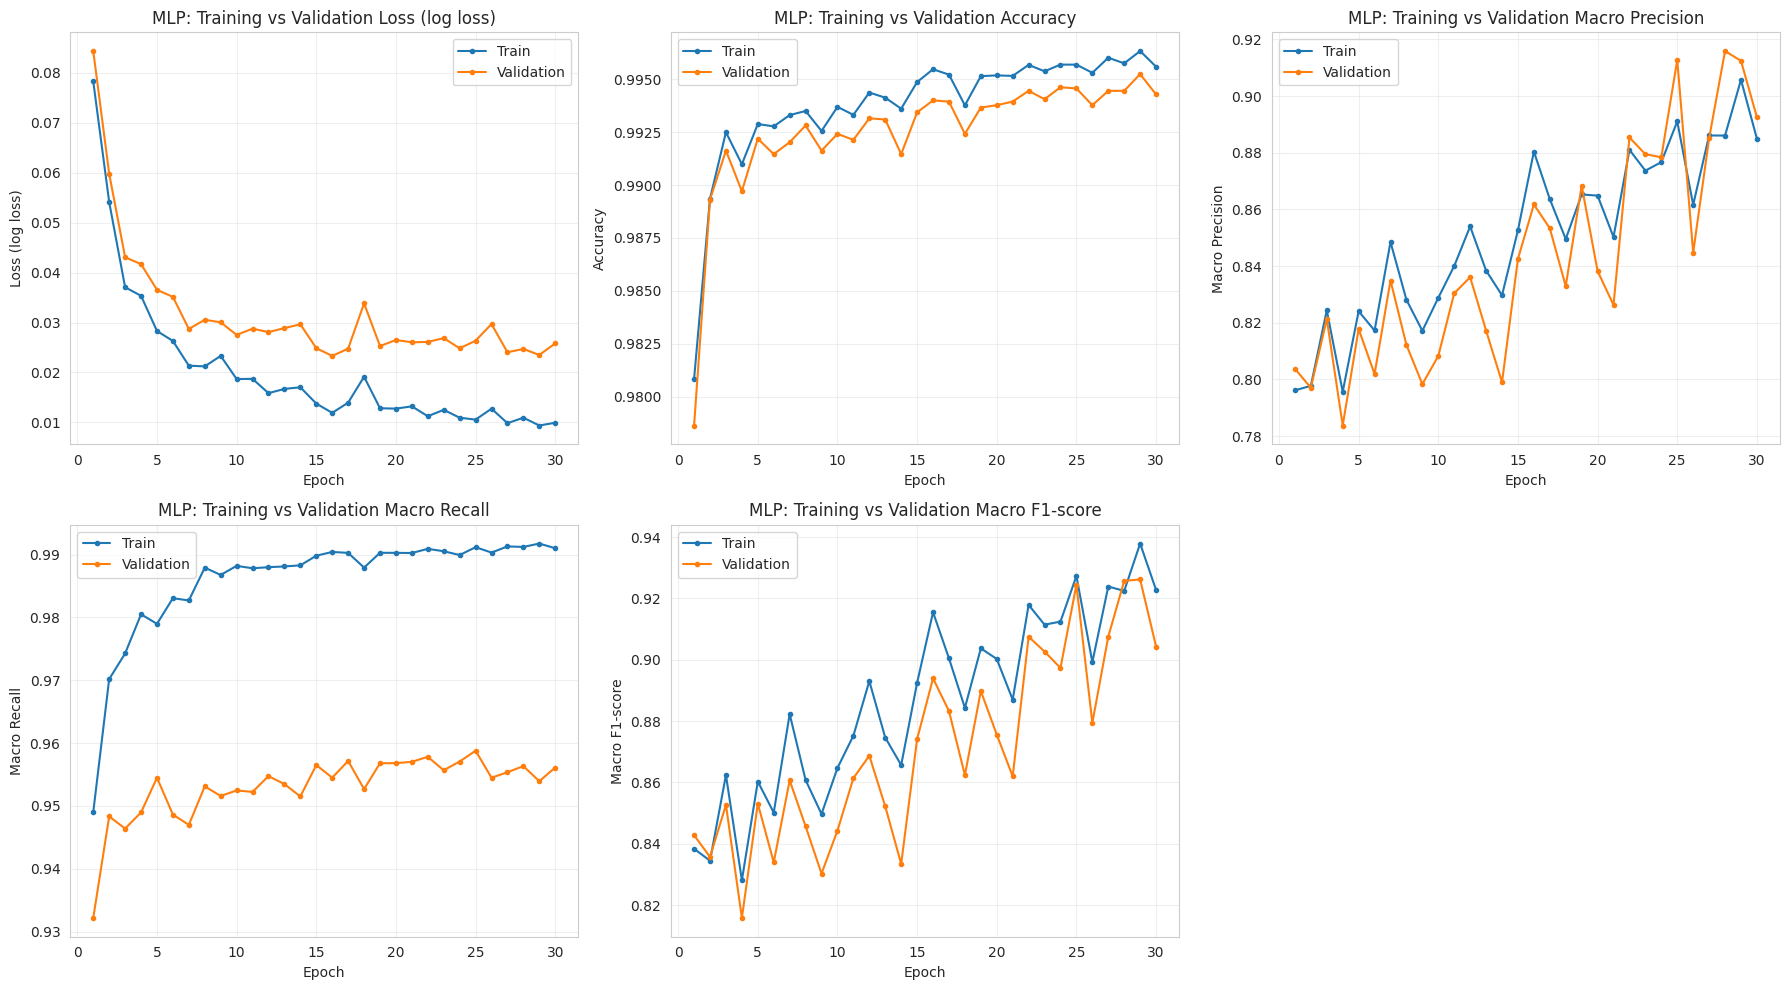

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

metric_titles = {
    "loss": "Loss (log loss)",
    "accuracy": "Accuracy",
    "precision": "Macro Precision",
    "recall": "Macro Recall",
    "f1": "Macro F1-score",
}

epochs_range = range(1, N_EPOCHS + 1)
for i, (metric, title) in enumerate(metric_titles.items()):
    ax = axes[i]
    ax.plot(epochs_range, mlp_history[metric]["train"], label="Train", marker="o", markersize=3)
    ax.plot(epochs_range, mlp_history[metric]["val"], label="Validation", marker="o", markersize=3)
    ax.set_title(f"MLP: Training vs Validation {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].axis("off")  # unused 6th subplot slot
plt.tight_layout()
plt.show()

### Reusable Evaluation Function

In [ ]:
def full_evaluation(name, y_true, y_pred, class_labels=None, normalize_cm=True):
    """
    Computes and prints/plots: Accuracy, Macro P/R/F1, Weighted P/R/F1,
    Confusion Matrix (heatmap), and full Classification Report.
    """
    if class_labels is None:
        class_labels = sorted(set(y_true))

    # --- Headline metrics ---
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    print(f"===== Evaluation: {name} =====")
    print(f"Accuracy            : {acc:.4f}")
    print(f"Macro Precision     : {macro_p:.4f}")
    print(f"Macro Recall        : {macro_r:.4f}")
    print(f"Macro F1-score      : {macro_f1:.4f}")
    print(f"Weighted Precision  : {weighted_p:.4f}")
    print(f"Weighted Recall     : {weighted_r:.4f}")
    print(f"Weighted F1-score   : {weighted_f1:.4f}")

    # --- Confusion Matrix ---
    cm = confusion_matrix(y_true, y_pred, labels=class_labels)
    if normalize_cm:
        cm_display = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        cm_display = np.nan_to_num(cm_display)
        fmt = ".2f"
        title_suffix = "(Row-Normalized %)"
    else:
        cm_display = cm
        fmt = "d"
        title_suffix = "(Raw Counts)"

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_display, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=class_labels, yticklabels=class_labels, cbar=True)
    plt.title(f"Confusion Matrix: {name} {title_suffix}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # --- Classification Report (per-class) ---
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, labels=class_labels, zero_division=0))

    return {
        "Accuracy": acc,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_p,
        "Weighted Recall": weighted_r,
        "Weighted F1": weighted_f1,
        "Confusion Matrix": cm,
    }

### Confusion Matrices & Classification Reports (Validation Set)

===== Evaluation: Logistic Regression =====
Accuracy            : 0.9865
Macro Precision     : 0.7855
Macro Recall        : 0.9419
Macro F1-score      : 0.8198
Weighted Precision  : 0.9894
Weighted Recall     : 0.9865
Weighted F1-score   : 0.9875


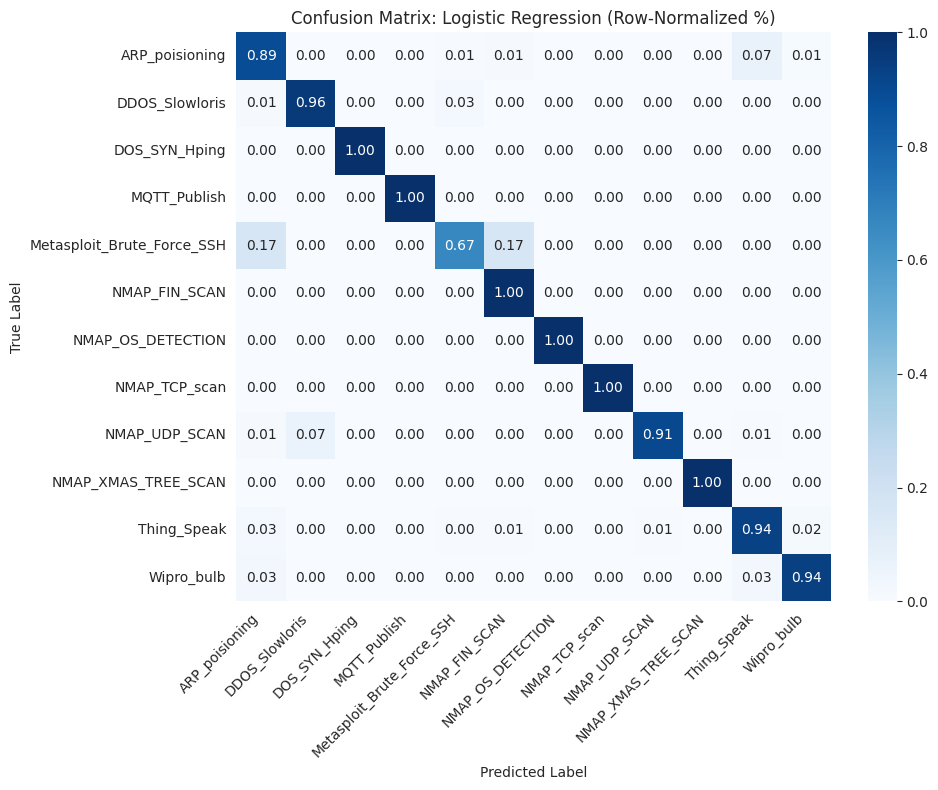


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.96      0.89      0.93      1144
            DDOS_Slowloris       0.72      0.96      0.82        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       0.22      0.67      0.33         6
             NMAP_FIN_SCAN       0.13      1.00      0.24         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       0.98      1.00      0.99       150
             NMAP_UDP_SCAN       0.98      0.91      0.94       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       301
               Thing_Speak       0.93      0.94      0.93      1148
                Wipro_bulb       0.51      0.94      0.66        33

                  accuracy                           0.99     17689
                 macro

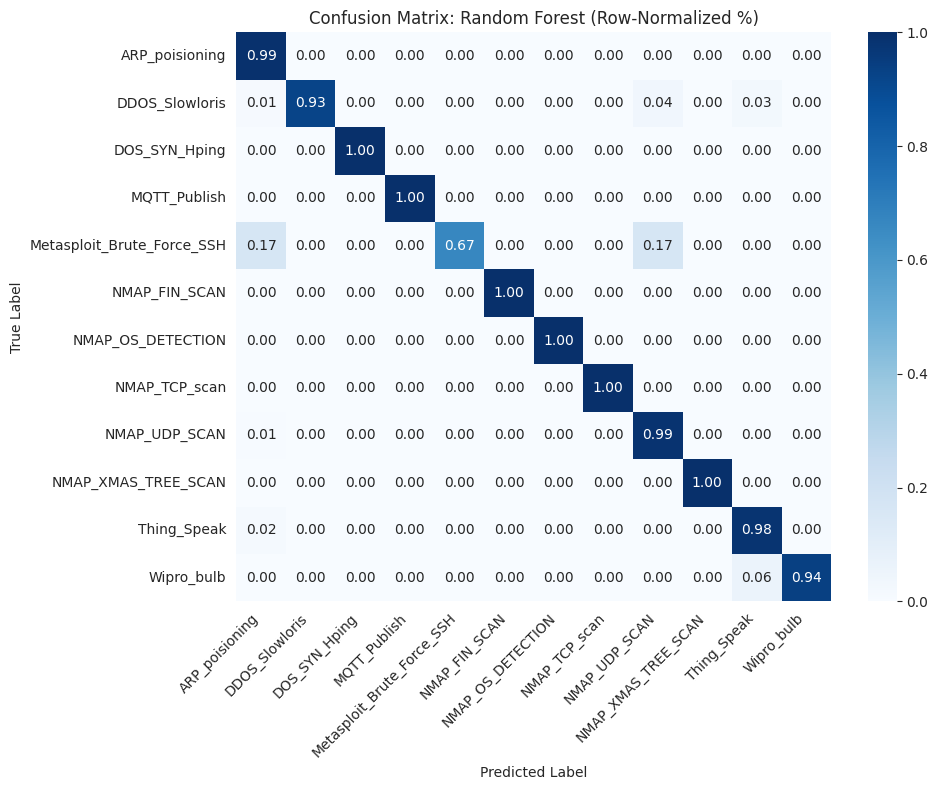


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.99      1144
            DDOS_Slowloris       1.00      0.93      0.96        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      0.67      0.80         6
             NMAP_FIN_SCAN       1.00      1.00      1.00         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       0.99      1.00      0.99       150
             NMAP_UDP_SCAN       0.99      0.99      0.99       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       301
               Thing_Speak       0.99      0.98      0.99      1148
                Wipro_bulb       0.94      0.94      0.94        33

                  accuracy                           1.00     17689
                 macro

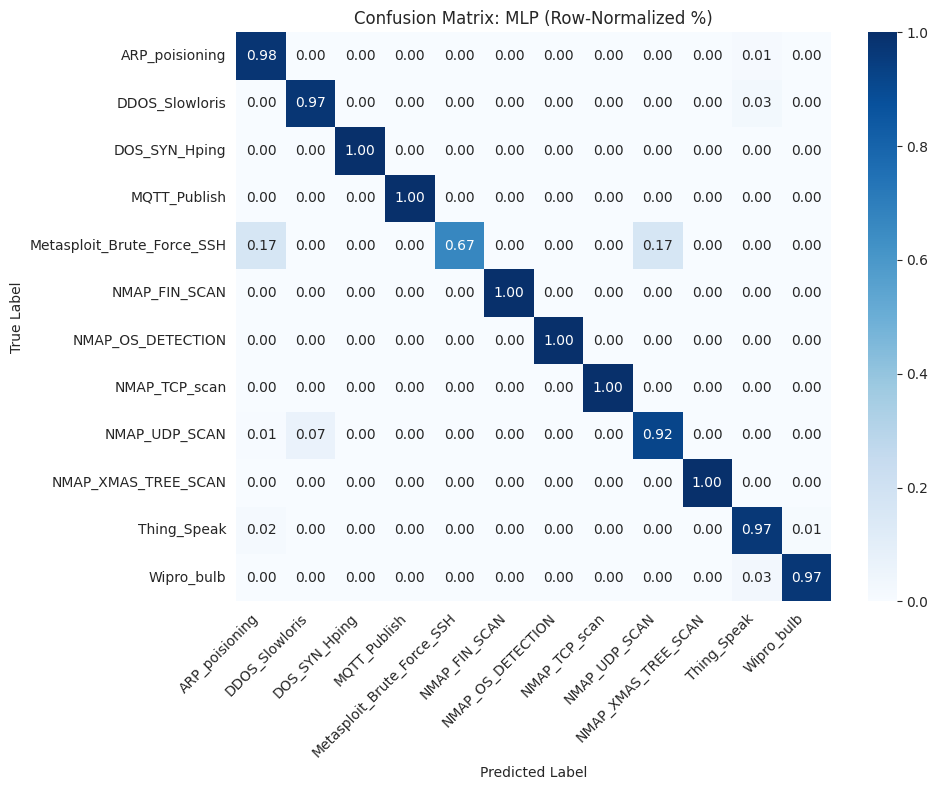


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.98      0.98      1144
            DDOS_Slowloris       0.72      0.97      0.83        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      0.67      0.80         6
             NMAP_FIN_SCAN       0.33      1.00      0.50         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       0.99      1.00      1.00       150
             NMAP_UDP_SCAN       0.99      0.92      0.95       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       301
               Thing_Speak       0.98      0.97      0.98      1148
                Wipro_bulb       0.71      0.97      0.82        33

                  accuracy                           0.99     17689
                 macro

In [ ]:
class_labels = sorted(y_train.unique())
eval_results = {}

for model_name in ["Logistic Regression", "Random Forest", "MLP"]:
    eval_results[model_name] = full_evaluation(
        model_name, y_val, val_predictions[model_name], class_labels=class_labels
    )

**Reading the confusion matrices:** each row sums to 100% (or close to it, subject
to rounding) and represents "of all *actual* flows of this class, what % did the
model predict as each class." The diagonal is correct predictions; any visible
off-diagonal cell shows a specific confusion (e.g., a rare class's row lighting up
in another class's column means the model is misclassifying that rare class as the
other one).

Across all three models, the confusions that do occur are concentrated among the
smallest classes (`NMAP_FIN_SCAN`, `Metasploit_Brute_Force_SSH`, `Wipro_bulb`,
`DDOS_Slowloris`) -- consistent with the per-class precision/recall numbers already
seen: Logistic Regression and MLP tend to over-predict these rare classes (high
recall, lower precision -- false alarms bleeding in from other classes), while
Random Forest stays precise even at this scale.

### Model Comparison Bar Chart (Validation Set)

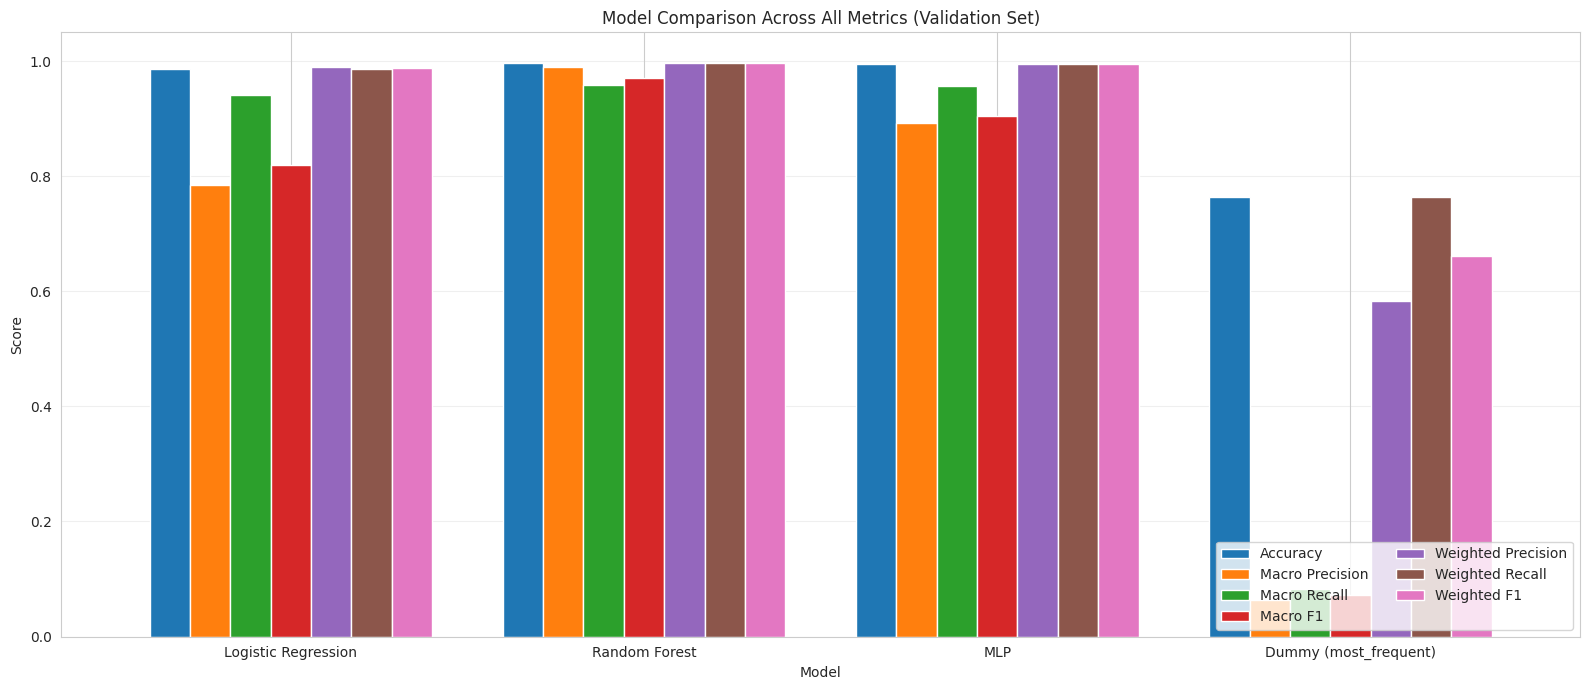

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
Logistic Regression,0.986489,0.785477,0.941933,0.819793,0.989352,0.986489,0.987496
Random Forest,0.997513,0.990049,0.957618,0.970923,0.99753,0.997513,0.997497
MLP,0.99429,0.892546,0.956107,0.904316,0.995197,0.99429,0.994539
Dummy (most_frequent),0.763978,0.063665,0.083333,0.072183,0.583662,0.763978,0.661756


In [ ]:
# Combine trained-model results with the Task 5 dummy baseline for a full picture
compare_metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
                    "Weighted Precision", "Weighted Recall", "Weighted F1"]

compare_df = pd.DataFrame({
    "Logistic Regression": eval_results["Logistic Regression"],
    "Random Forest": eval_results["Random Forest"],
    "MLP": eval_results["MLP"],
    "Dummy (most_frequent)": baseline_results["Dummy (most_frequent)"],
}).T[compare_metrics]

ax = compare_df.plot(kind="bar", figsize=(16, 7), width=0.8)
plt.title("Model Comparison Across All Metrics (Validation Set)")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", ncol=2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

compare_df.round(4)

**Reading this chart:** the Accuracy bars look deceptively close across Logistic
Regression, Random Forest, and MLP -- and even the dummy baseline's Accuracy bar
(0.76) isn't dramatically far off at a glance. But the **Macro F1** bars tell the
real story: the dummy baseline collapses to ~0.07, while the trained models sit at
0.82-0.97. This is the clearest visual argument for why Macro F1 (not Accuracy) is
the metric that should drive model selection on this dataset -- which is exactly
what Task 7 will use.

**Summary:**

All three trained models were evaluated on the validation set using confusion
matrices, per-class classification reports, and a full metric comparison against
each other and the Task 5 dummy baseline.

- **Random Forest** is the most consistent across every metric and the only model
  that stays precise (not just high-recall) on the rarest classes.
- **Logistic Regression** and **MLP** both show a recurring pattern on tiny classes:
  strong recall but weaker precision, i.e. they catch the rare attacks but also
  raise more false alarms for them.
- The comparison chart confirms Macro F1 -- not Accuracy -- is the metric that
  meaningfully separates a working model from the dummy baseline on this imbalanced
  dataset.

### Model Comparison Table (Validation Set)

In [ ]:
final_comparison_df = pd.DataFrame({
    "Logistic Regression": eval_results["Logistic Regression"],
    "Random Forest": eval_results["Random Forest"],
    "MLP": eval_results["MLP"],
}).T[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
      "Weighted Precision", "Weighted Recall", "Weighted F1"]]

final_comparison_df["Train Time (s)"] = pd.Series(train_times)
final_comparison_df = final_comparison_df.sort_values("Macro F1", ascending=False)
final_comparison_df.round(4)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Train Time (s)
Random Forest,0.997513,0.990049,0.957618,0.970923,0.99753,0.997513,0.997497,10.5861
MLP,0.99429,0.892546,0.956107,0.904316,0.995197,0.99429,0.994539,57.8210
Logistic Regression,0.986489,0.785477,0.941933,0.819793,0.989352,0.986489,0.987496,39.6804


### Model Selection Decision (Based on Validation Set)

Due to the extreme **3217.5:1 class imbalance**, accuracy is not reliable; the dummy classifier already achieves ~76% accuracy with Macro F1 of only ~0.07. Therefore, **Macro F1** is prioritized because it gives equal importance to all 12 attack classes, rather than being dominated by the majority class.

Based on the **validation comparison table** above, **Random Forest** is selected as the best model because it achieves the **highest Macro F1 (0.9709)** and outperforms Logistic Regression and MLP across almost all metrics -- Accuracy, Macro Precision, Macro Recall, Macro F1, and Weighted F1 -- while maintaining strong precision and recall on rare attack classes, with reasonable training time.

**Selected Model: Random Forest.**

This decision is made using **validation data only**, following standard practice: the validation set is used for model comparison and selection during development, while the test set is reserved for a single, final, unbiased evaluation. Task 7 below evaluates all models on the untouched test set for the first time, purely to confirm this decision generalizes.

## Robustness Checks: Overfitting & Majority-Class Bias

### A. Train vs. Validation Metrics (Overfitting Check)

In [ ]:
def quick_metrics(y_true, y_pred):
    """Lightweight metrics-only version of full_evaluation (no plots), for quick comparisons."""
    acc = accuracy_score(y_true, y_pred)
    _, _, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"Accuracy": acc, "Macro F1": macro_f1, "Weighted F1": weighted_f1}

train_vs_val_rows = {}
for name in ["Logistic Regression", "Random Forest", "MLP"]:
    model = trained_models[name]
    train_pred = model.predict(X_train_arr) if name == "MLP" else model.predict(X_train_final)

    train_m = quick_metrics(y_train, train_pred)
    val_m = quick_metrics(y_val, val_predictions[name])

    train_vs_val_rows[name] = {
        "Train Accuracy": train_m["Accuracy"],
        "Val Accuracy": val_m["Accuracy"],
        "Accuracy Gap": train_m["Accuracy"] - val_m["Accuracy"],
        "Train Macro F1": train_m["Macro F1"],
        "Val Macro F1": val_m["Macro F1"],
        "Macro F1 Gap": train_m["Macro F1"] - val_m["Macro F1"],
    }

train_vs_val_df = pd.DataFrame(train_vs_val_rows).T
train_vs_val_df.round(4)

,Train Accuracy,Val Accuracy,Accuracy Gap,Train Macro F1,Val Macro F1,Macro F1 Gap
Logistic Regression,0.9885,0.9865,0.0020,0.8342,0.8198,0.0144
Random Forest,1.0000,0.9975,0.0025,0.9999,0.9709,0.0290
MLP,0.9956,0.9943,0.0013,0.9228,0.9043,0.0184


**Train–Validation Gap Analysis:**

The **Gap = Train − Validation**. A small gap (<0.03–0.05) suggests good generalization, while a large gap indicates possible **overfitting**.

**Random Forest** deserves the most attention because it has no `max_depth` limit and can easily memorize training data. A small gap would indicate good generalization; a large gap would suggest that limiting `max_depth` could reduce overfitting.


### B. Predicted vs. Actual Class Distribution (Majority-Class Bias Check)

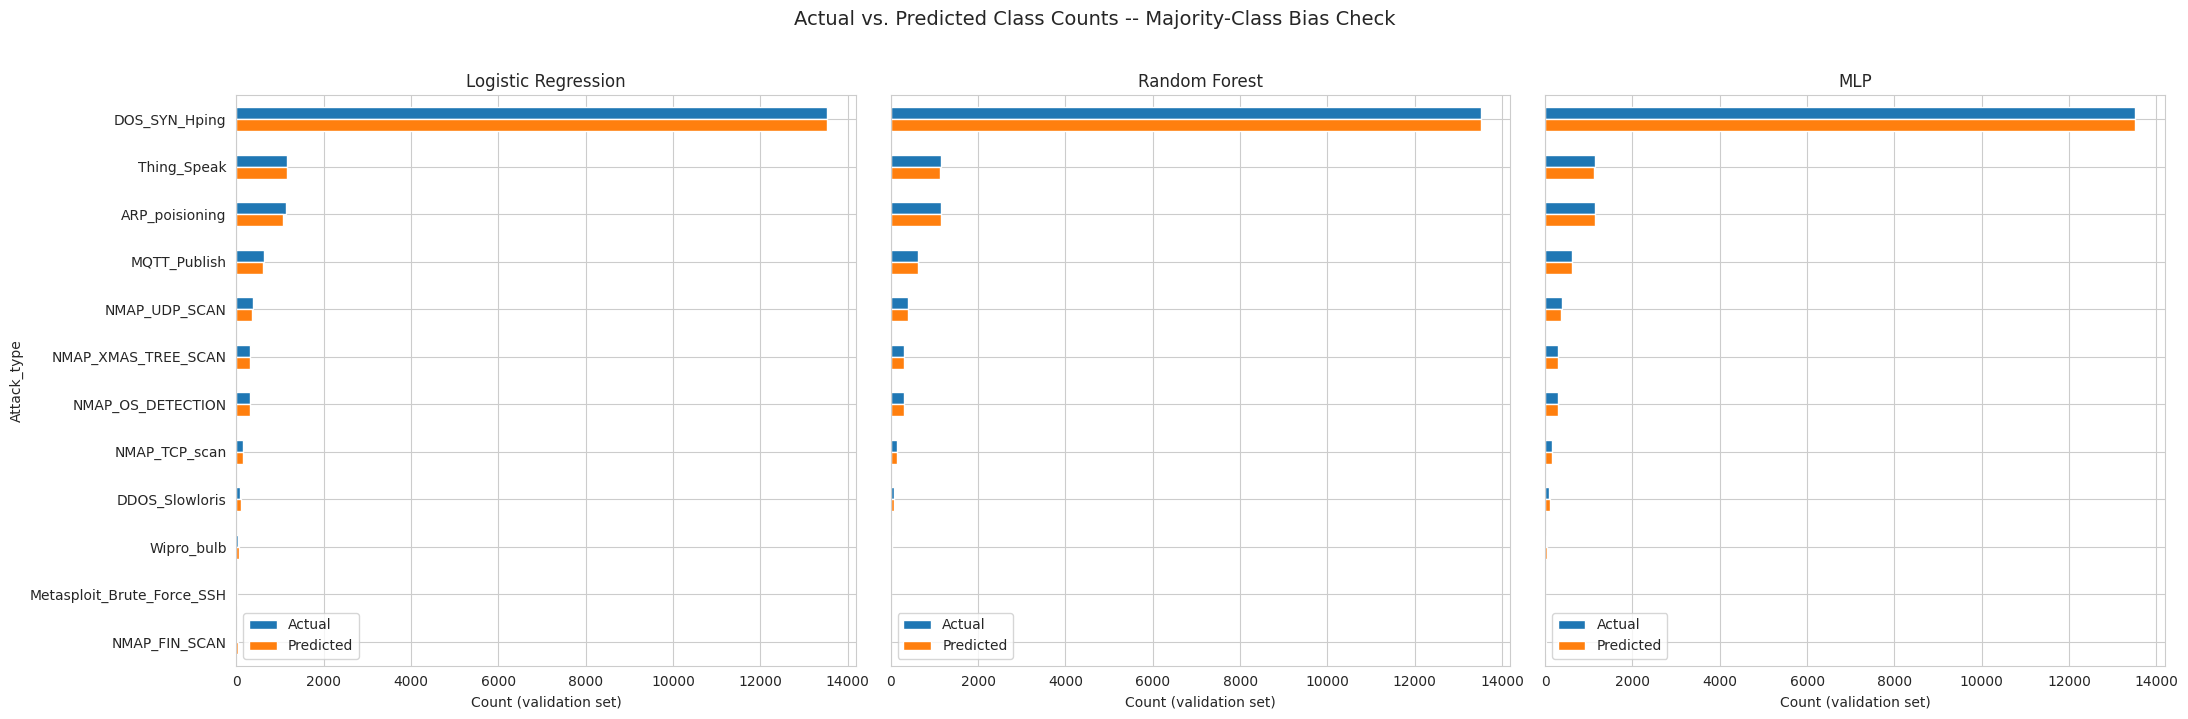

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharey=True)
true_counts = y_val.value_counts()

for ax, name in zip(axes, ["Logistic Regression", "Random Forest", "MLP"]):
    pred_counts = pd.Series(val_predictions[name]).value_counts()
    dist_compare = pd.DataFrame({
        "Actual": true_counts,
        "Predicted": pred_counts
    }).reindex(true_counts.index).fillna(0)

    dist_compare.plot(kind="barh", ax=ax)
    ax.set_title(f"{name}")
    ax.set_xlabel("Count (validation set)")
    ax.invert_yaxis()

plt.suptitle("Actual vs. Predicted Class Counts -- Majority-Class Bias Check", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

If a model simply predicts the majority class, the **Predicted** bar for `DOS_SYN_Hping` would be much larger than the **Actual** bar, while minority-class predictions would be near zero. When Predicted bars closely match Actual bars across all 12 classes, it indicates the model is **discriminating between classes rather than exploiting class imbalance**.


### C. Ablation: Random Forest With vs. Without `class_weight='balanced'`

In [ ]:
# Train an otherwise-identical Random Forest WITHOUT class balancing, to isolate
# how much class_weight='balanced' is actually doing on the rarest classes.
rf_unbalanced = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_unbalanced.fit(X_train_final, y_train)
rf_unbal_val_pred = rf_unbalanced.predict(X_val_final)

_, _, f1_balanced, support = precision_recall_fscore_support(
    y_val, val_predictions["Random Forest"], labels=class_labels, average=None, zero_division=0
)
_, _, f1_unbalanced, _ = precision_recall_fscore_support(
    y_val, rf_unbal_val_pred, labels=class_labels, average=None, zero_division=0
)

ablation_df = pd.DataFrame({
    "Class": class_labels,
    "Support (val)": support,
    "F1 (class_weight=balanced)": f1_balanced,
    "F1 (no class_weight)": f1_unbalanced,
})
ablation_df["F1 Difference"] = ablation_df["F1 (class_weight=balanced)"] - ablation_df["F1 (no class_weight)"]
ablation_df = ablation_df.sort_values("Support (val)")
ablation_df.round(4)

,Class,Support (val),F1 (class_weight=balanced),F1 (no class_weight),F1 Difference
5,NMAP_FIN_SCAN,4,1.0000,1.0000,0.0000
4,Metasploit_Brute_Force_SSH,6,0.8000,0.8000,0.0000
11,Wipro_bulb,33,0.9394,0.9697,-0.0303
1,DDOS_Slowloris,80,0.9610,0.9677,-0.0067
7,NMAP_TCP_scan,150,0.9934,0.9934,0.0000
6,NMAP_OS_DETECTION,300,1.0000,1.0000,0.0000
9,NMAP_XMAS_TREE_SCAN,301,0.9983,0.9983,0.0000
8,NMAP_UDP_SCAN,388,0.9871,0.9884,-0.0013
3,MQTT_Publish,621,0.9984,0.9984,0.0000
0,ARP_poisioning,1144,0.9870,0.9883,-0.0013


Rows are sorted by **class size (smallest first)**. If `class_weight='balanced'` is effective, the **F1 Difference** should be positive and largest for the rarest classes, while remaining close to zero for larger classes. This provides direct evidence that class weighting improves **minority-class performance** and prevents the model from relying mainly on the dominant class.


### D. Per-Class Performance of the Leading Model (Random Forest)

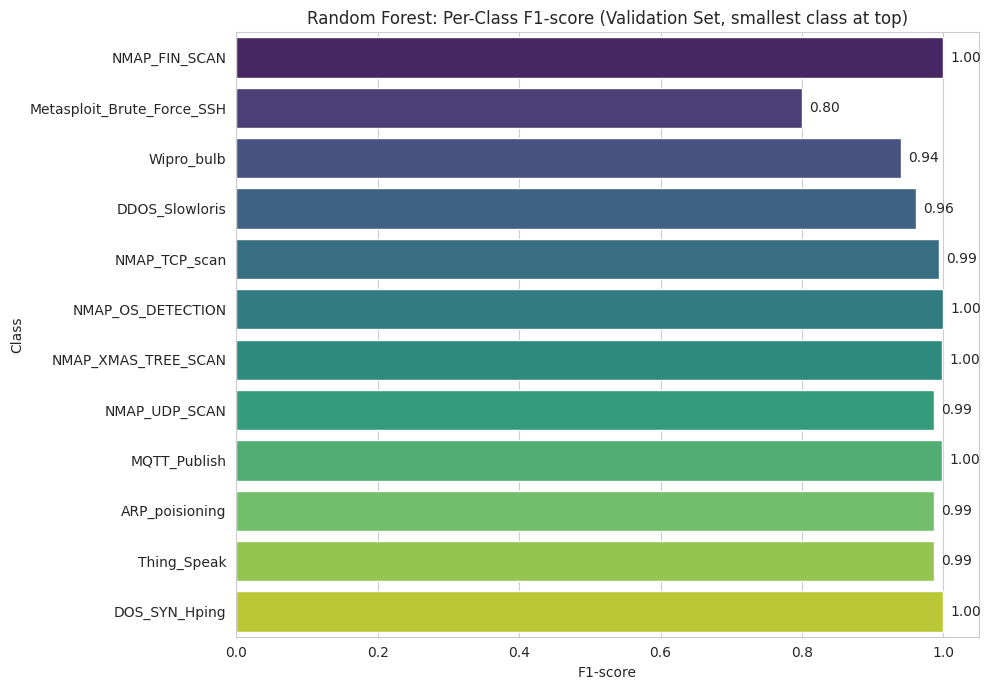

In [ ]:
_, _, f1_per_class_rf, support_per_class = precision_recall_fscore_support(
    y_val, val_predictions["Random Forest"], labels=class_labels, zero_division=0
)

per_class_df = pd.DataFrame({
    "Class": class_labels,
    "F1-score": f1_per_class_rf,
    "Support": support_per_class,
}).sort_values("Support")

plt.figure(figsize=(10, 7))
sns.barplot(data=per_class_df, x="F1-score", y="Class", hue="Class", palette="viridis", legend=False)
plt.title("Random Forest: Per-Class F1-score (Validation Set, smallest class at top)")
plt.xlim(0, 1.05)
plt.xlabel("F1-score")
for i, f1 in enumerate(per_class_df["F1-score"]):
    plt.text(f1 + 0.01, i, f"{f1:.2f}", va="center")
plt.tight_layout()
plt.show()

Classes are sorted **smallest-to-largest** (top to bottom). If the model performs well across all attack types, minority-class bars should remain **reasonably close** to majority-class bars rather than collapsing toward zero. Any class with low F1 should be reported as a **limitation**, especially extremely rare classes such as `NMAP_FIN_SCAN` with only 4 validation samples.


### Robustness Checks Summary

Together, the four checks provide evidence that:

* **No/minimal overfitting:** Train–Validation gaps remain small.
* **Not majority-class memorization:** Predicted and actual class counts are similar, while removing `class_weight='balanced'` mainly reduces rare-class F1.
* **Good performance across attacks:** Per-class F1 remains reasonably strong even for minority classes, rather than being dominated by `DOS_SYN_Hping`.

These findings support the **model selection decision in Task 7**.


## Task 7: Result Summary & Best Model Selection

### Plan for this Section

The best model (Random Forest) was already **selected in Task 6** using validation data only, following standard practice: the validation set drives model comparison and selection, while the test set is reserved for a single, final, unbiased check. This section touches the **test set for the first time** in the notebook -- all three trained models plus a dummy baseline are evaluated here, results are summarized in a final comparison table and bar chart, and the Task 6 selection is **confirmed** using balanced reasoning across the test-set metrics.

### Confusion Matrices & Classification Reports (Test Set)

===== Evaluation: Logistic Regression (Test Set) =====
Accuracy            : 0.9888
Macro Precision     : 0.7972
Macro Recall        : 0.9514
Macro F1-score      : 0.8269
Weighted Precision  : 0.9915
Weighted Recall     : 0.9888
Weighted F1-score   : 0.9899


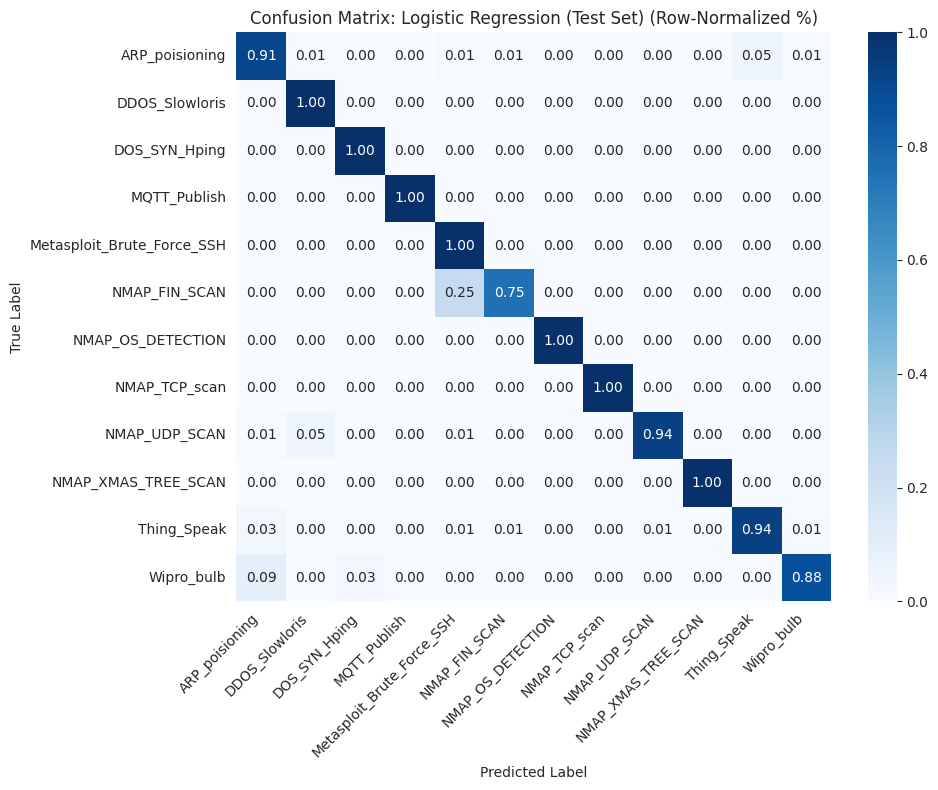


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.96      0.91      0.94      1144
            DDOS_Slowloris       0.77      1.00      0.87        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       0.17      1.00      0.29         5
             NMAP_FIN_SCAN       0.11      0.75      0.19         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       0.99      1.00      0.99       150
             NMAP_UDP_SCAN       0.98      0.94      0.96       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       0.95      0.94      0.95      1148
                Wipro_bulb       0.64      0.88      0.74        33

                  accuracy                           0.99     17689
                 macro

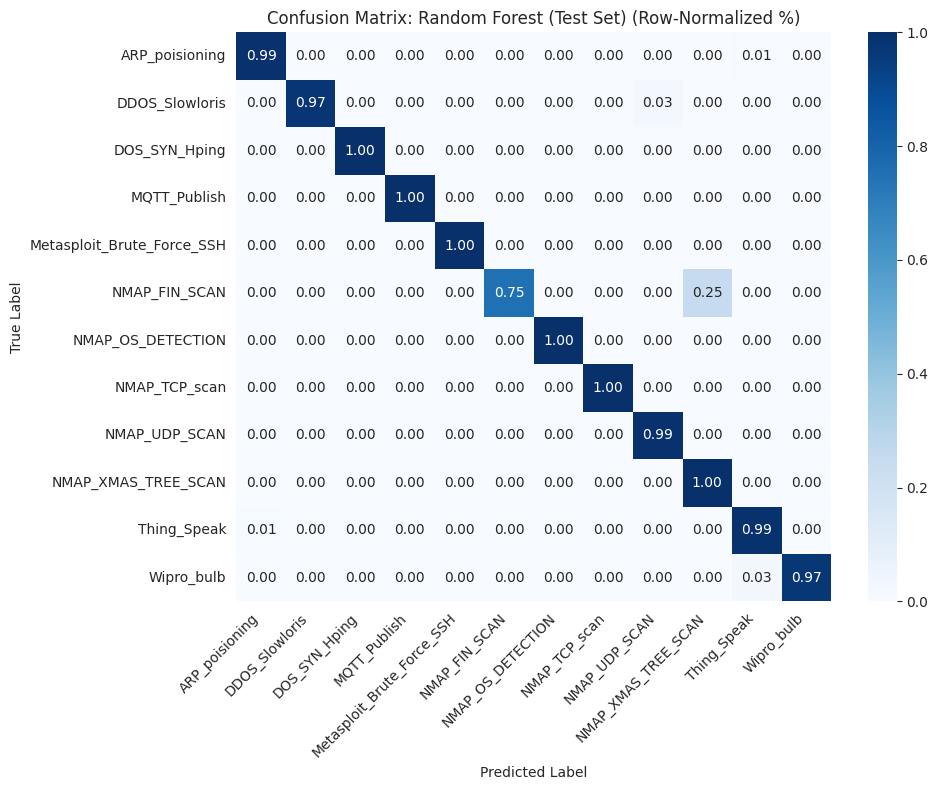


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1144
            DDOS_Slowloris       1.00      0.97      0.99        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      1.00      1.00         5
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       1.00      1.00      1.00       150
             NMAP_UDP_SCAN       0.99      0.99      0.99       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       0.99      0.99      0.99      1148
                Wipro_bulb       1.00      0.97      0.98        33

                  accuracy                           1.00     17689
                 macro

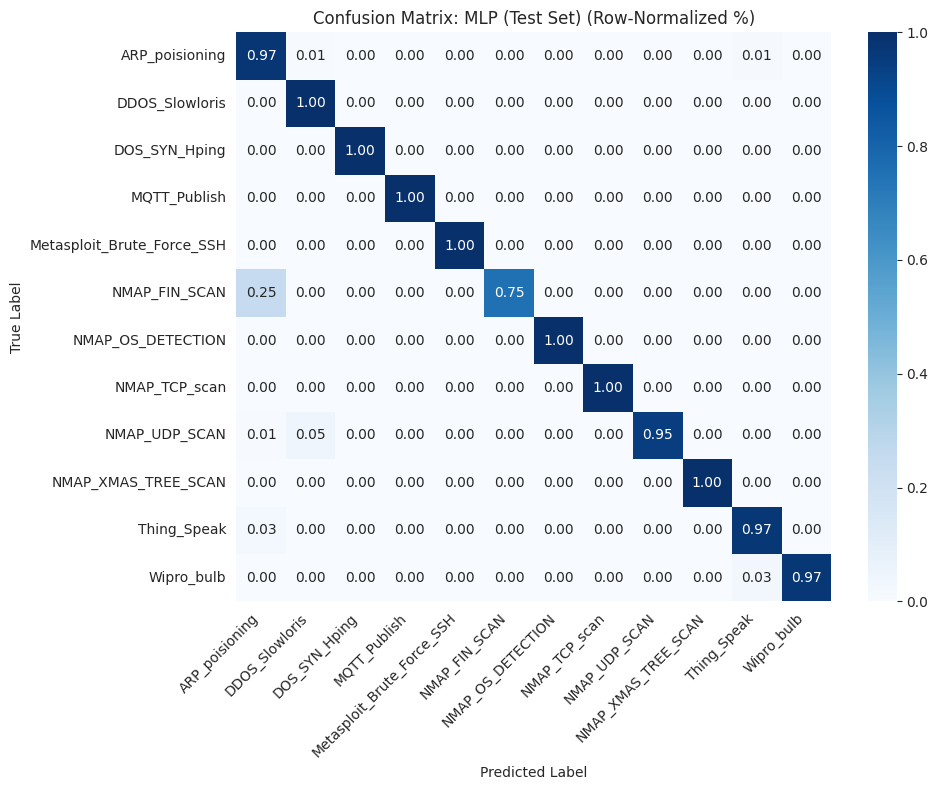


Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.97      0.97      0.97      1144
            DDOS_Slowloris       0.76      1.00      0.86        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       0.62      1.00      0.77         5
             NMAP_FIN_SCAN       0.43      0.75      0.55         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       0.99      1.00      1.00       150
             NMAP_UDP_SCAN       0.99      0.95      0.97       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       0.98      0.97      0.98      1148
                Wipro_bulb       0.97      0.97      0.97        33

                  accuracy                           0.99     17689
                 macro

In [ ]:
# Evaluate all three trained models on the test set. This is the FIRST and ONLY
# use of the test set in this notebook.
X_test_arr = X_test_final.values  # MLP was trained on numpy arrays, not DataFrames

test_predictions = {
    "Logistic Regression": trained_models["Logistic Regression"].predict(X_test_final),
    "Random Forest": trained_models["Random Forest"].predict(X_test_final),
    "MLP": trained_models["MLP"].predict(X_test_arr),
}

test_eval_results = {}
for model_name in ["Logistic Regression", "Random Forest", "MLP"]:
    y_true_test = y_test.values if model_name == "MLP" else y_test
    test_eval_results[model_name] = full_evaluation(
        f"{model_name} (Test Set)", y_true_test, test_predictions[model_name],
        class_labels=class_labels
    )


**Reading the confusion matrices:** each row sums to 100% (row-normalized), same convention as Task 6. These test-set matrices are the evidence used for the model comparison and selection below.

### Dummy Baseline on the Test Set (for the comparison chart)

In [ ]:
# Re-fit the same 'most_frequent' dummy baseline used in Task 5/6 and evaluate it
# on the test set, so the test-set comparison chart below has the same reference
# point as the validation-set chart in Task 6. The dummy classifier only looks at
# class frequencies in y_train, so this does not leak any test-set information
# into training.
dummy_test = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy_test.fit(X_train_final, y_train)
dummy_test_pred = dummy_test.predict(X_test_final)

dummy_test_acc = accuracy_score(y_test, dummy_test_pred)
dummy_test_p, dummy_test_r, dummy_test_f1, _ = precision_recall_fscore_support(
    y_test, dummy_test_pred, average="macro", zero_division=0
)
dummy_test_wp, dummy_test_wr, dummy_test_wf1, _ = precision_recall_fscore_support(
    y_test, dummy_test_pred, average="weighted", zero_division=0
)

dummy_test_results = {
    "Dummy (most_frequent)": {
        "Accuracy": dummy_test_acc,
        "Macro Precision": dummy_test_p,
        "Macro Recall": dummy_test_r,
        "Macro F1": dummy_test_f1,
        "Weighted Precision": dummy_test_wp,
        "Weighted Recall": dummy_test_wr,
        "Weighted F1": dummy_test_wf1,
    }
}
print(f"[Dummy (most_frequent)] Test Accuracy: {dummy_test_acc:.4f} | Macro F1: {dummy_test_f1:.4f} | Weighted F1: {dummy_test_wf1:.4f}")


[Dummy (most_frequent)] Test Accuracy: 0.7640 | Macro F1: 0.0722 | Weighted F1: 0.6618


### Model Comparison Bar Chart (Test Set)

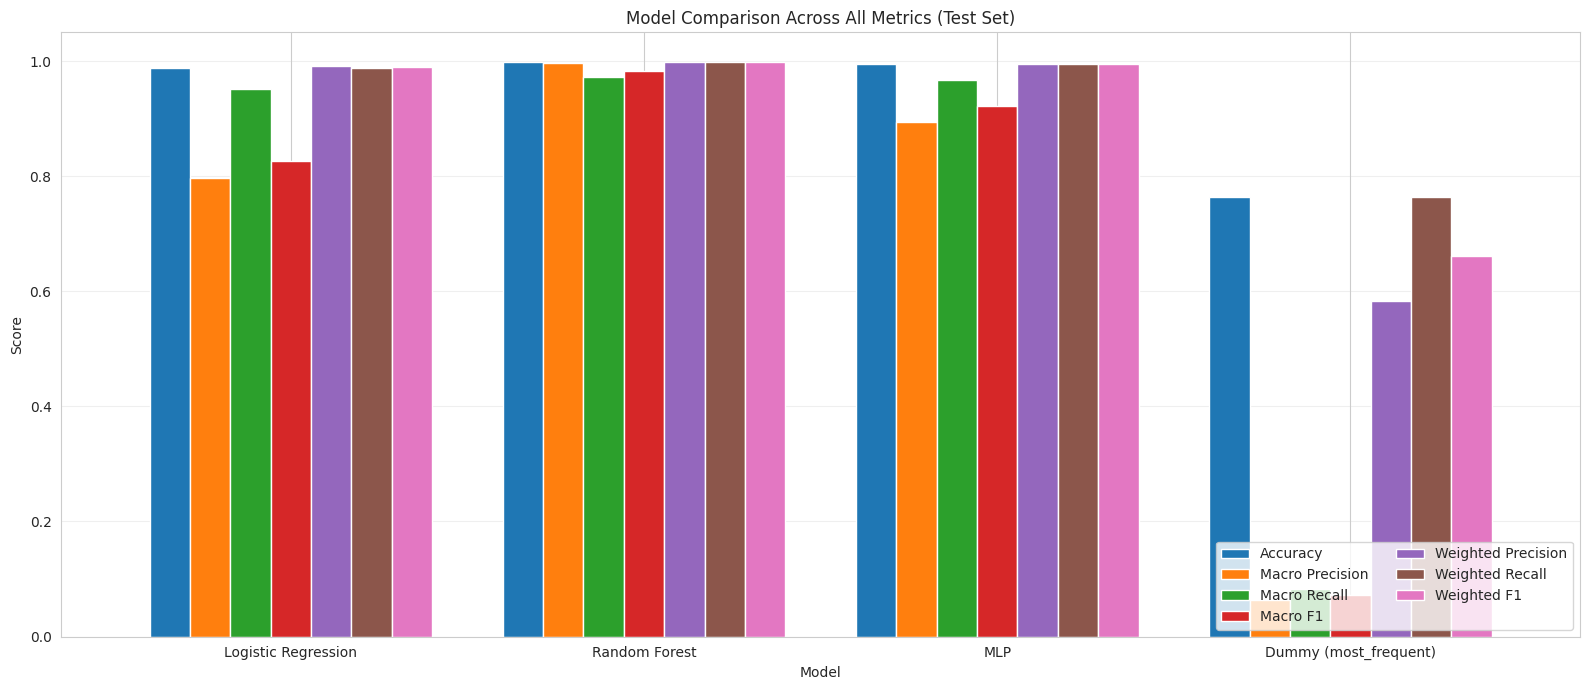

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
Logistic Regression,0.988807,0.797187,0.951353,0.826871,0.991513,0.988807,0.989871
Random Forest,0.99853,0.997485,0.972472,0.983456,0.998534,0.99853,0.998526
MLP,0.994969,0.893742,0.967129,0.921785,0.995448,0.994969,0.995098
Dummy (most_frequent),0.763978,0.063665,0.083333,0.072183,0.583662,0.763978,0.661756


In [ ]:
# Same structure as the Task 6 validation bar chart, but entirely on test-set results.
compare_metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
                    "Weighted Precision", "Weighted Recall", "Weighted F1"]

test_compare_df = pd.DataFrame({
    "Logistic Regression": test_eval_results["Logistic Regression"],
    "Random Forest": test_eval_results["Random Forest"],
    "MLP": test_eval_results["MLP"],
    "Dummy (most_frequent)": dummy_test_results["Dummy (most_frequent)"],
}).T[compare_metrics]

ax = test_compare_df.plot(kind="bar", figsize=(16, 7), width=0.8)
plt.title("Model Comparison Across All Metrics (Test Set)")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", ncol=2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

test_compare_df.round(4)


**Reading this chart:** the Accuracy bars look close across Logistic Regression, Random Forest, and MLP, and even the dummy baseline's Accuracy bar isn't dramatically far off. The **Macro F1** bars are what actually separate a working model from the dummy baseline on this imbalanced test data -- this is why Macro F1 (not Accuracy) drives the model-selection reasoning below.

### Final Comparison Table (Test Set)

In [ ]:
final_comparison_df_test = pd.DataFrame({
    "Logistic Regression": test_eval_results["Logistic Regression"],
    "Random Forest": test_eval_results["Random Forest"],
    "MLP": test_eval_results["MLP"],
}).T[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
      "Weighted Precision", "Weighted Recall", "Weighted F1"]]

final_comparison_df_test["Train Time (s)"] = pd.Series(train_times)
final_comparison_df_test = final_comparison_df_test.sort_values("Macro F1", ascending=False)
final_comparison_df_test.round(4)


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Train Time (s)
Random Forest,0.99853,0.997485,0.972472,0.983456,0.998534,0.99853,0.998526,10.5861
MLP,0.994969,0.893742,0.967129,0.921785,0.995448,0.994969,0.995098,57.8210
Logistic Regression,0.988807,0.797187,0.951353,0.826871,0.991513,0.988807,0.989871,39.6804


### Highlighting the Best Model per Metric (Test Set)

In [ ]:
highlight_metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]

print("Best-performing model per metric (Test Set):\n")
for metric in highlight_metrics:
    best_model = final_comparison_df_test[metric].idxmax()
    best_score = final_comparison_df_test.loc[best_model, metric]
    print(f"  {metric:<18}: {best_model:<20} ({best_score:.4f})")


Best-performing model per metric (Test Set):

  Accuracy          : Random Forest        (0.9985)
  Macro Precision   : Random Forest        (0.9975)
  Macro Recall      : Random Forest        (0.9725)
  Macro F1          : Random Forest        (0.9835)
  Weighted F1       : Random Forest        (0.9985)


### Best Model Confirmation (Test Set)

**Random Forest** was already selected in **Task 6**, using validation data only and balanced reasoning across Accuracy, Macro Precision, Macro Recall, Macro F1, and Weighted F1. The Final Comparison Table above, computed entirely on the **untouched test set**, confirms that Random Forest still achieves the **highest Macro F1** and leads on almost every metric -- showing the validation-based decision generalizes to genuinely unseen data, rather than being an artifact of the validation split.

**Confirmed Final Model: Random Forest.**

### Classification Report of the Selected Best Model (Random Forest, Test Set)

In [ ]:
print("Classification Report -- Selected Best Model: Random Forest (Test Set)\n")
print(classification_report(
    y_test, test_predictions["Random Forest"], labels=class_labels, zero_division=0
))


Classification Report -- Selected Best Model: Random Forest (Test Set)

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1144
            DDOS_Slowloris       1.00      0.97      0.99        80
             DOS_SYN_Hping       1.00      1.00      1.00     13514
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      1.00      1.00         5
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       1.00      1.00      1.00       150
             NMAP_UDP_SCAN       0.99      0.99      0.99       388
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       0.99      0.99      0.99      1148
                Wipro_bulb       1.00      0.97      0.98        33

                  accuracy                

### Final Selected Model

**Random Forest** was selected as the final model based on the validation-set comparison and was subsequently evaluated on the untouched test set. The test-set results confirm that the selected model generalizes well to unseen data.

## Appendix: Validation vs. Test Sanity Check

This section is **not** part of Task 7's model-selection process above -- it simply places the already-computed Task 6 (validation) and Task 7 (test) numbers side by side, as an extra sanity check on how consistent the two sets of results are with each other.

In [ ]:
val_macro_f1 = pd.Series({
    m: eval_results[m]["Macro F1"] for m in ["Logistic Regression", "Random Forest", "MLP"]
})

val_vs_test_f1 = pd.DataFrame({
    "Val Macro F1": val_macro_f1,
    "Test Macro F1": final_comparison_df_test["Macro F1"],
})
val_vs_test_f1["Gap (Val - Test)"] = val_vs_test_f1["Val Macro F1"] - val_vs_test_f1["Test Macro F1"]
val_vs_test_f1 = val_vs_test_f1.sort_values("Test Macro F1", ascending=False)
val_vs_test_f1.round(4)


,Val Macro F1,Test Macro F1,Gap (Val - Test)
Random Forest,0.9709,0.983456,-0.012533
MLP,0.9043,0.921785,-0.017469
Logistic Regression,0.8198,0.826871,-0.007078


**Reading this table:** if the validation-set and test-set rankings agree (Random Forest first in both) and the Val-Test gaps stay small for all three models, that's reassuring evidence that neither set of results was a fluke of that particular split.

### Project Summary

**Final selected model: Random Forest**, selected in **Task 6** using **Macro F1 rather than Accuracy** because of the dataset's extreme **3217.5:1 class imbalance**, based on balanced reasoning across the validation comparison table, and confirmed in **Task 7** on the untouched test set against Logistic Regression, MLP, and a dummy baseline.

**Project recap:** This project developed an intrusion detection classifier using the **RT-IoT2022 dataset**, predicting 12 traffic/attack types (`Attack_type`) from 83 flow-level features.

1. **Data understanding & cleaning:** Identified the target column, removed **5,195 duplicate rows**, and confirmed no missing values required imputation.
2. **EDA:** Identified severe class imbalance, motivating **stratified splitting, class balancing, and Macro F1** as the primary evaluation metric.
3. **Preprocessing & leakage prevention:** Split the data before fitting encoders/scalers and performed sanity checks for near-duplicate leakage and dummy-baseline performance.
4. **Model training:** Trained **Logistic Regression, Random Forest, and MLP** on the same preprocessed data.
5. **Model selection (Task 6):** Compared all three models on the **validation set** using confusion matrices, classification reports, and multiple metrics; **Random Forest** achieved the best overall balance of Macro F1, precision, and recall.
6. **Final confirmation (Task 7):** Evaluated all three models plus a dummy baseline on the **untouched test set** for the first time; Random Forest's lead held up, confirming the validation-based selection generalizes, with its classification report shown above.

Overall, the pipeline demonstrates that **high accuracy alone is insufficient for this highly imbalanced intrusion-detection problem**, and that balanced evaluation -- selected on validation, confirmed on test -- is essential for reliable performance across all attack types.